<a href="https://colab.research.google.com/github/4nanyarana/deepharmonics-/blob/main/DeepHarmonics_01_Data_Exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import sys
import os

print("Python version:", sys.version)
print("Workspace:", os.getcwd())

Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Workspace: /content


In [2]:
!git clone --depth 1 https://github.com/jukedeck/nottingham-dataset.git

Cloning into 'nottingham-dataset'...
remote: Enumerating objects: 3103, done.
remote: Counting objects: 100% (3103/3103), done.
remote: Compressing objects: 100% (1678/1678), done.
remote: Total 3103 (delta 1424), reused 3101 (delta 1424), pack-reused 0 (from 0)
Receiving objects: 100% (3103/3103), 877.46 KiB | 9.33 MiB/s, done.
Resolving deltas: 100% (1424/1424), done.


In [3]:
import os

midi_dir = "/content/nottingham-dataset/MIDI"

midi_files = [
    f for f in os.listdir(midi_dir)
    if f.lower().endswith((".mid", ".midi"))
]

print("Total MIDI files found:", len(midi_files))
print("\nFirst 10 files:")

for filename in midi_files[:10]:
    print(filename)

Total MIDI files found: 1034

First 10 files:
morris6.mid
reelsd-g11.mid
jigs49.mid
reelsr-t14.mid
ashover1.mid
jigs2.mid
reelsr-t8.mid
reelsu-z22.mid
jigs4.mid
waltzes21.mid


In [4]:
license_path = "/content/nottingham-dataset/LICENSE.md"

if os.path.exists(license_path):
    with open(license_path, "r", encoding="utf-8") as f:
        print(f.read()[:4000])
else:
    print("Licence file not found at this path.")
    print("Inspect the downloaded repository before proceeding.")

                    GNU GENERAL PUBLIC LICENSE
                       Version 3, 29 June 2007

 Copyright (C) 2007 Free Software Foundation, Inc. <http://fsf.org/>
 Everyone is permitted to copy and distribute verbatim copies
 of this license document, but changing it is not allowed.

                            Preamble

  The GNU General Public License is a free, copyleft license for
software and other kinds of works.

  The licenses for most software and other practical works are designed
to take away your freedom to share and change the works.  By contrast,
the GNU General Public License is intended to guarantee your freedom to
share and change all versions of a program--to make sure it remains free
software for all its users.  We, the Free Software Foundation, use the
GNU General Public License for most of our software; it applies also to
any other work released this way by its authors.  You can apply it to
your programs, too.

  When we speak of free software, we are referring to

In [5]:
!pip install pretty_midi

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.6/5.6 MB 48.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.6/54.6 kB 4.3 MB/s eta 0:00:00


In [6]:
import os
import pretty_midi

midi_dir = "/content/nottingham-dataset/MIDI"

# Select the first MIDI file
filename = sorted([
    f for f in os.listdir(midi_dir)
    if f.lower().endswith((".mid", ".midi"))
])[0]

file_path = os.path.join(midi_dir, filename)

# Read the music file
midi_data = pretty_midi.PrettyMIDI(file_path)

print("File name:", filename)
print("Duration:", round(midi_data.get_end_time(), 2), "seconds")
print("Number of instruments:", len(midi_data.instruments))
print("Total notes:", sum(
    len(instrument.notes)
    for instrument in midi_data.instruments
))

File name: ashover1.mid
Duration: 47.5 seconds
Number of instruments: 2
Total notes: 158


/usr/local/lib/python3.13/dist-packages/pretty_midi/pretty_midi.py:122: RuntimeWarning: Tempo, Key or Time signature change events found on non-zero tracks.  This is not a valid type 0 or type 1 MIDI file.  Tempo, Key or Time Signature may be wrong.
  warnings.warn(


In [7]:
for instrument in midi_data.instruments:
    print("Instrument:", instrument.name)
    print("Number of notes:", len(instrument.notes))

    for note in instrument.notes[:10]:
        print(
            "Pitch:", note.pitch,
            "| Start:", round(note.start, 2),
            "| End:", round(note.end, 2),
            "| Velocity:", note.velocity
        )

Instrument: 
Number of notes: 68
Pitch: 76 | Start: 1.0 | End: 1.5 | Velocity: 90
Pitch: 74 | Start: 1.5 | End: 2.5 | Velocity: 90
Pitch: 71 | Start: 2.5 | End: 3.0 | Velocity: 90
Pitch: 69 | Start: 3.0 | End: 3.75 | Velocity: 90
Pitch: 71 | Start: 3.75 | End: 4.0 | Velocity: 90
Pitch: 72 | Start: 4.0 | End: 4.5 | Velocity: 90
Pitch: 71 | Start: 4.5 | End: 5.5 | Velocity: 90
Pitch: 67 | Start: 5.5 | End: 6.0 | Velocity: 90
Pitch: 69 | Start: 6.0 | End: 7.0 | Velocity: 90
Pitch: 76 | Start: 7.0 | End: 7.5 | Velocity: 90
Instrument: 
Number of notes: 90
Pitch: 43 | Start: 1.5 | End: 3.0 | Velocity: 90
Pitch: 47 | Start: 1.5 | End: 3.0 | Velocity: 90
Pitch: 50 | Start: 1.5 | End: 3.0 | Velocity: 90
Pitch: 38 | Start: 3.0 | End: 4.5 | Velocity: 90
Pitch: 42 | Start: 3.0 | End: 4.5 | Velocity: 90
Pitch: 45 | Start: 3.0 | End: 4.5 | Velocity: 90
Pitch: 43 | Start: 4.5 | End: 6.0 | Velocity: 90
Pitch: 47 | Start: 4.5 | End: 6.0 | Velocity: 90
Pitch: 50 | Start: 4.5 | End: 6.0 | Velocity: 90
P

In [8]:

import os
import warnings
import statistics
import pretty_midi

midi_dir = "/content/nottingham-dataset/MIDI"

midi_files = sorted([
    f for f in os.listdir(midi_dir)
    if f.lower().endswith((".mid", ".midi"))
])

durations = []
note_counts = []
instrument_counts = []
pitch_values = []

failed_files = []
files_with_warnings = []

for filename in midi_files:
    path = os.path.join(midi_dir, filename)

    try:
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            midi = pretty_midi.PrettyMIDI(path)

        if caught:
            files_with_warnings.append(filename)

        notes = [
            note
            for instrument in midi.instruments
            for note in instrument.notes
        ]

        durations.append(midi.get_end_time())
        note_counts.append(len(notes))
        instrument_counts.append(len(midi.instruments))
        pitch_values.extend(note.pitch for note in notes)

    except Exception as error:
        failed_files.append((filename, str(error)))

print("Total files discovered:", len(midi_files))
print("Files loaded:", len(durations))
print("Files that failed:", len(failed_files))
print("Files with MIDI warnings:", len(files_with_warnings))

if durations:
    print("\nDuration (seconds)")
    print("Shortest:", round(min(durations), 2))
    print("Median:", round(statistics.median(durations), 2))
    print("Longest:", round(max(durations), 2))

    print("\nNotes per file")
    print("Fewest:", min(note_counts))
    print("Median:", statistics.median(note_counts))
    print("Most:", max(note_counts))

    print("\nInstruments per file")
    print("Minimum:", min(instrument_counts))
    print("Maximum:", max(instrument_counts))

if pitch_values:
    print("\nPitch range")
    print("Lowest MIDI pitch:", min(pitch_values))
    print("Highest MIDI pitch:", max(pitch_values))

print("\nFirst 10 files with warnings:", files_with_warnings[:10])
print("\nFirst 10 failed files:", failed_files[:10])

Total files discovered: 1034
Files loaded: 1034
Files that failed: 0
Files with MIDI warnings: 1021

Duration (seconds)
Shortest: 12.0
Median: 64.0
Longest: 769.5

Notes per file
Fewest: 24
Median: 301.0
Most: 3868

Instruments per file
Minimum: 1
Maximum: 2

Pitch range
Lowest MIDI pitch: 36
Highest MIDI pitch: 88

First 10 files with warnings: ['ashover1.mid', 'ashover10.mid', 'ashover11.mid', 'ashover12.mid', 'ashover13.mid', 'ashover14.mid', 'ashover15.mid', 'ashover16.mid', 'ashover17.mid', 'ashover18.mid']

First 10 failed files: []


In [9]:

import os
import mido

midi_dir = "/content/nottingham-dataset/MIDI"
filename = "ashover1.mid"
path = os.path.join(midi_dir, filename)

raw_midi = mido.MidiFile(path)

print("File:", filename)
print("MIDI type:", raw_midi.type)
print("Ticks per beat:", raw_midi.ticks_per_beat)
print("Number of raw tracks:", len(raw_midi.tracks))

for track_number, track in enumerate(raw_midi.tracks):
    print(f"\nTrack {track_number}: {track.name!r}")

    for message in track:
        if message.is_meta and message.type in (
            "set_tempo",
            "time_signature",
            "key_signature"
        ):
            print(" ", message)

File: ashover1.mid
MIDI type: 1
Ticks per beat: 1024
Number of raw tracks: 2

Track 0: ''
  MetaMessage('key_signature', key='G', time=0)
  MetaMessage('time_signature', numerator=3, denominator=4, clocks_per_click=24, notated_32nd_notes_per_beat=8, time=0)
  MetaMessage('time_signature', numerator=2, denominator=4, clocks_per_click=24, notated_32nd_notes_per_beat=8, time=0)
  MetaMessage('time_signature', numerator=3, denominator=4, clocks_per_click=24, notated_32nd_notes_per_beat=8, time=0)
  MetaMessage('time_signature', numerator=2, denominator=4, clocks_per_click=24, notated_32nd_notes_per_beat=8, time=0)
  MetaMessage('time_signature', numerator=3, denominator=4, clocks_per_click=24, notated_32nd_notes_per_beat=8, time=0)
  MetaMessage('time_signature', numerator=2, denominator=4, clocks_per_click=24, notated_32nd_notes_per_beat=8, time=0)
  MetaMessage('time_signature', numerator=3, denominator=4, clocks_per_click=24, notated_32nd_notes_per_beat=8, time=0)
  MetaMessage('time_si

In [10]:

import mido
from collections import Counter

raw_midi = mido.MidiFile(
    "/content/nottingham-dataset/MIDI/ashover1.mid"
)

for track_number, track in enumerate(raw_midi.tracks):
    print(f"\n--- Track {track_number} ---")

    absolute_tick = 0
    metadata_count = Counter()

    for message in track:
        absolute_tick += message.time

        if message.is_meta and message.type in (
            "set_tempo",
            "time_signature",
            "key_signature"
        ):
            metadata_count[message.type] += 1

            print(
                "Tick:", absolute_tick,
                "| Type:", message.type,
                "| Details:", message
            )

    print("Metadata event counts:", dict(metadata_count))


--- Track 0 ---
Tick: 0 | Type: key_signature | Details: MetaMessage('key_signature', key='G', time=0)
Tick: 0 | Type: time_signature | Details: MetaMessage('time_signature', numerator=3, denominator=4, clocks_per_click=24, notated_32nd_notes_per_beat=8, time=0)
Tick: 21504 | Type: time_signature | Details: MetaMessage('time_signature', numerator=2, denominator=4, clocks_per_click=24, notated_32nd_notes_per_beat=8, time=0)
Tick: 23552 | Type: time_signature | Details: MetaMessage('time_signature', numerator=3, denominator=4, clocks_per_click=24, notated_32nd_notes_per_beat=8, time=0)
Tick: 45056 | Type: time_signature | Details: MetaMessage('time_signature', numerator=2, denominator=4, clocks_per_click=24, notated_32nd_notes_per_beat=8, time=0)
Tick: 47104 | Type: time_signature | Details: MetaMessage('time_signature', numerator=3, denominator=4, clocks_per_click=24, notated_32nd_notes_per_beat=8, time=0)
Tick: 68608 | Type: time_signature | Details: MetaMessage('time_signature', nume

In [11]:

import pretty_midi
import mido

path = "/content/nottingham-dataset/MIDI/ashover1.mid"

raw = mido.MidiFile(path)
parsed = pretty_midi.PrettyMIDI(path)

print("Raw MIDI type:", raw.type)
print("Raw tempo events:", sum(
    1 for track in raw.tracks
    for msg in track
    if msg.is_meta and msg.type == "set_tempo"
))
print("Raw time-signature events:", sum(
    1 for track in raw.tracks
    for msg in track
    if msg.is_meta and msg.type == "time_signature"
))

print("\nMetadata retained by pretty_midi:")
print("Tempo changes:", parsed.get_tempo_changes())
print("Time signatures:", [
    (ts.numerator, ts.denominator, round(ts.time, 3))
    for ts in parsed.time_signature_changes
])
print("Note count:", sum(
    len(inst.notes) for inst in parsed.instruments
))
print("Duration:", round(parsed.get_end_time(), 2), "seconds")

Raw MIDI type: 1
Raw tempo events: 0
Raw time-signature events: 18

Metadata retained by pretty_midi:
Tempo changes: (array([0.]), array([120.]))
Time signatures: [(3, 4, np.float64(0.0)), (2, 4, np.float64(10.5)), (3, 4, np.float64(11.5)), (2, 4, np.float64(22.0)), (3, 4, np.float64(23.0)), (2, 4, np.float64(33.5)), (3, 4, np.float64(34.5)), (2, 4, np.float64(45.0)), (3, 4, np.float64(46.0))]
Note count: 158
Duration: 47.5 seconds


/usr/local/lib/python3.13/dist-packages/pretty_midi/pretty_midi.py:122: RuntimeWarning: Tempo, Key or Time signature change events found on non-zero tracks.  This is not a valid type 0 or type 1 MIDI file.  Tempo, Key or Time Signature may be wrong.
  warnings.warn(


In [12]:

import os
import mido
from collections import Counter

midi_dir = "/content/nottingham-dataset/MIDI"
files = sorted(
    f for f in os.listdir(midi_dir)
    if f.lower().endswith((".mid", ".midi"))
)

stats = Counter()
examples = []

for filename in files:
    midi = mido.MidiFile(os.path.join(midi_dir, filename))

    def metadata_events(track):
        events = []
        tick = 0

        for msg in track:
            tick += msg.time

            if msg.is_meta and msg.type in (
                "set_tempo",
                "time_signature",
                "key_signature"
            ):
                events.append((tick, msg.type, str(msg)))

        return events

    track_events = [
        metadata_events(track) for track in midi.tracks
    ]

    stats["files"] += 1
    if not any(
        event_type == "set_tempo"
        for track in midi.tracks
        for event_type in [msg.type for msg in track if msg.is_meta]
    ):
        stats["no_explicit_tempo"] += 1

    if len(track_events) > 1 and track_events[1]:
        stats["metadata_on_track_1"] += 1

        if set(track_events[1]).issubset(set(track_events[0])):
            stats["track_1_metadata_duplicated"] += 1
        elif len(examples) < 5:
            examples.append((filename, track_events[0], track_events[1]))

print("Dataset metadata audit:")
for key, value in stats.items():
    print(f"{key}: {value}")

print("\nExamples where track 1 metadata is not fully duplicated:")
for example in examples:
    print(example)

Dataset metadata audit:
files: 1034
no_explicit_tempo: 1034
metadata_on_track_1: 1021
track_1_metadata_duplicated: 989

Examples where track 1 metadata is not fully duplicated:
('ashover41.mid', [(0, 'key_signature', "MetaMessage('key_signature', key='G', time=0)"), (0, 'time_signature', "MetaMessage('time_signature', numerator=4, denominator=4, clocks_per_click=24, notated_32nd_notes_per_beat=8, time=0)"), (65536, 'key_signature', "MetaMessage('key_signature', key='A', time=0)")], [(0, 'key_signature', "MetaMessage('key_signature', key='G', time=0)"), (0, 'time_signature', "MetaMessage('time_signature', numerator=4, denominator=4, clocks_per_click=24, notated_32nd_notes_per_beat=8, time=0)"), (61440, 'key_signature', "MetaMessage('key_signature', key='A', time=0)")])
('jigs124.mid', [(0, 'key_signature', "MetaMessage('key_signature', key='G', time=0)"), (0, 'time_signature', "MetaMessage('time_signature', numerator=6, denominator=8, clocks_per_click=24, notated_32nd_notes_per_beat=8, 

LSTM Experiment


In [13]:
import os
import warnings
import numpy as np
import pretty_midi
from collections import Counter

DATA_DIR = "/content/nottingham-dataset/MIDI"

midi_files = sorted([
    f for f in os.listdir(DATA_DIR)
    if f.lower().endswith((".mid", ".midi"))
])

print("MIDI files available:", len(midi_files))
print("Original dataset directory:", DATA_DIR)

MIDI files available: 1034
Original dataset directory: /content/nottingham-dataset/MIDI


In [14]:
# Duration boundaries in seconds.
# np.digitize assigns each duration to a category.
DURATION_BINS = [
    0.125, 0.25, 0.375, 0.5, 0.75,
    1.0, 1.5, 2.0, 3.0, 4.0
]

# Time between consecutive note starts, in seconds.
GAP_BINS = [
    0.0625, 0.125, 0.25, 0.5, 1.0,
    2.0, 4.0
]

events_by_file = {}
warning_files = []
failed_files = []

for filename in midi_files:
    path = os.path.join(DATA_DIR, filename)

    try:
        # Record warnings instead of printing hundreds of messages.
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            midi = pretty_midi.PrettyMIDI(path)

        if caught:
            warning_files.append(filename)

        # Collect notes from every instrument track.
        notes = []

        for part_id, instrument in enumerate(midi.instruments):
            for note in instrument.notes:
                notes.append({
                    "part": part_id,
                    "pitch": int(note.pitch),
                    "start": float(note.start),
                    "duration": float(note.end - note.start)
                })

        # Sort deterministically by start time, then part and pitch.
        notes.sort(
            key=lambda n: (n["start"], n["part"], n["pitch"])
        )

        if not notes:
            continue

        events = []
        previous_start = 0.0

        for note in notes:
            duration = max(0.0, note["duration"])
            gap = max(0.0, note["start"] - previous_start)

            duration_bin = int(
                np.digitize(duration, DURATION_BINS)
            )
            gap_bin = int(
                np.digitize(gap, GAP_BINS)
            )

            event = (
                note["part"],
                note["pitch"],
                duration_bin,
                gap_bin
            )

            events.append(event)
            previous_start = note["start"]

        events_by_file[filename] = events

    except Exception as error:
        failed_files.append((filename, str(error)))

print("Files converted:", len(events_by_file))
print("Files with warnings:", len(warning_files))
print("Files that failed:", len(failed_files))
print("First failed files:", failed_files[:5])

Files converted: 1034
Files with warnings: 1021
Files that failed: 0
First failed files: []


In [15]:
all_events = [
    event
    for events in events_by_file.values()
    for event in events
]

print("Pieces represented:", len(events_by_file))
print("Total note events:", len(all_events))

if all_events:
    print(
        "Unique event types:",
        len(set(all_events))
    )

    print(
        "Pitch range:",
        min(event[1] for event in all_events),
        "to",
        max(event[1] for event in all_events)
    )

    print("\nFirst 10 events from one piece:")
    first_piece = next(iter(events_by_file.values()))

    for event in first_piece[:10]:
        print(
            f"Part={event[0]}, "
            f"Pitch={event[1]}, "
            f"Duration bin={event[2]}, "
            f"Start-gap bin={event[3]}"
        )

Pieces represented: 1034
Total note events: 356269
Unique event types: 1035
Pitch range: 36 to 88

First 10 events from one piece:
Part=0, Pitch=76, Duration bin=4, Start-gap bin=5
Part=0, Pitch=74, Duration bin=6, Start-gap bin=4
Part=1, Pitch=43, Duration bin=7, Start-gap bin=0
Part=1, Pitch=47, Duration bin=7, Start-gap bin=0
Part=1, Pitch=50, Duration bin=7, Start-gap bin=0
Part=0, Pitch=71, Duration bin=4, Start-gap bin=5
Part=0, Pitch=69, Duration bin=5, Start-gap bin=4
Part=1, Pitch=38, Duration bin=7, Start-gap bin=0
Part=1, Pitch=42, Duration bin=7, Start-gap bin=0
Part=1, Pitch=45, Duration bin=7, Start-gap bin=0


In [16]:

import random
from collections import Counter

# Fixed seed: running this cell again gives the same split.
SEED = 42
rng = random.Random(SEED)

piece_names = sorted(events_by_file.keys())
rng.shuffle(piece_names)

n = len(piece_names)
train_end = int(0.80 * n)
val_end = int(0.90 * n)

train_names = piece_names[:train_end]
val_names = piece_names[train_end:val_end]
test_names = piece_names[val_end:]

# Build the vocabulary using TRAINING pieces only.
train_event_counts = Counter(
    event
    for name in train_names
    for event in events_by_file[name]
)

UNK = ("<UNK>",)
vocab_events = sorted(train_event_counts.keys())
event_to_id = {event: idx for idx, event in enumerate(vocab_events)}
event_to_id[UNK] = len(event_to_id)

def count_unknown_events(names):
    total = 0
    unknown = 0

    for name in names:
        for event in events_by_file[name]:
            total += 1
            if event not in event_to_id:
                unknown += 1

    return total, unknown

print("Pieces in dataset:", n)
print(f"Training pieces:   {len(train_names)} ({len(train_names)/n:.1%})")
print(f"Validation pieces: {len(val_names)} ({len(val_names)/n:.1%})")
print(f"Test pieces:       {len(test_names)} ({len(test_names)/n:.1%})")
print("Training vocabulary size (including UNK):", len(event_to_id))

for split_name, names in [
    ("Training", train_names),
    ("Validation", val_names),
    ("Test", test_names),
]:
    total, unknown = count_unknown_events(names)
    percentage = 100 * unknown / total if total else 0
    print(
        f"{split_name}: {total:,} events | "
        f"{unknown:,} unknown ({percentage:.2f}%)"
    )

print("\nExample training event:", vocab_events[0])
print("Its integer ID:", event_to_id[vocab_events[0]])

Pieces in dataset: 1034
Training pieces:   827 (80.0%)
Validation pieces: 103 (10.0%)
Test pieces:       104 (10.1%)
Training vocabulary size (including UNK): 978
Training: 285,715 events | 0 unknown (0.00%)
Validation: 34,296 events | 123 unknown (0.36%)
Test: 36,258 events | 72 unknown (0.20%)

Example training event: (0, 55, 2, 0)
Its integer ID: 0


In [17]:
import numpy as np

SEQUENCE_LENGTH = 64

def encode_piece(filename):
    """Convert one piece's events into integer IDs."""
    events = events_by_file[filename]

    return np.array(
        [event_to_id.get(event, event_to_id[UNK]) for event in events],
        dtype=np.int64
    )

def make_sequences(piece_names, sequence_length=SEQUENCE_LENGTH):
    """
    Create input sequences and next-event targets.
    Sequences never cross piece boundaries.
    """
    X = []
    y = []

    for filename in piece_names:
        ids = encode_piece(filename)

        if len(ids) <= sequence_length:
            continue

        for start in range(len(ids) - sequence_length):
            X.append(ids[start:start + sequence_length])
            y.append(ids[start + sequence_length])

    X = np.asarray(X, dtype=np.int64)
    y = np.asarray(y, dtype=np.int64)

    return X, y


X_train, y_train = make_sequences(train_names)
X_val, y_val = make_sequences(val_names)
X_test, y_test = make_sequences(test_names)

print("Training inputs:", X_train.shape)
print("Training targets:", y_train.shape)

print("Validation inputs:", X_val.shape)
print("Validation targets:", y_val.shape)

print("Test inputs:", X_test.shape)
print("Test targets:", y_test.shape)

print("\nFirst input sequence shape:", X_train[0].shape)
print("First target event ID:", y_train[0])
print("Vocabulary size:", len(event_to_id))

Training inputs: (232834, 64)
Training targets: (232834,)
Validation inputs: (27704, 64)
Validation targets: (27704,)
Test inputs: (29602, 64)
Test targets: (29602,)

First input sequence shape: (64,)
First target event ID: 939
Vocabulary size: 978


In [18]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Using CPU")

print("\nData checks:")
print("X_train dtype:", X_train.dtype)
print("y_train dtype:", y_train.dtype)
print("Training inputs contain only valid IDs:",
      X_train.min() >= 0 and X_train.max() < len(event_to_id))
print("Training targets contain only valid IDs:",
      y_train.min() >= 0 and y_train.max() < len(event_to_id))

PyTorch version: 2.11.0+cpu
CUDA available: False
Using CPU

Data checks:
X_train dtype: int64
y_train dtype: int64
Training inputs contain only valid IDs: True
Training targets contain only valid IDs: True


In [19]:

import random
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Training device:", device)

# Convert NumPy arrays to PyTorch tensors.
# from_numpy shares memory where possible.
train_dataset = TensorDataset(
    torch.from_numpy(X_train),
    torch.from_numpy(y_train)
)
val_dataset = TensorDataset(
    torch.from_numpy(X_val),
    torch.from_numpy(y_val)
)

BATCH_SIZE = 256

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

class MusicLSTM(nn.Module):
    def __init__(
        self,
        vocab_size,
        embedding_dim=64,
        hidden_size=96
    ):
        super().__init__()

        self.embedding = nn.Embedding(vocab_size, embedding_dim)
        self.dropout = nn.Dropout(0.1)
        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_size,
            batch_first=True
        )
        self.output = nn.Linear(hidden_size, vocab_size)

    def forward(self, x):
        # x shape: (batch_size, sequence_length)
        x = self.embedding(x)
        x = self.dropout(x)

        # Use the final LSTM output to predict the next event.
        sequence_output, _ = self.lstm(x)
        last_output = sequence_output[:, -1, :]

        return self.output(last_output)


model = MusicLSTM(
    vocab_size=len(event_to_id),
    embedding_dim=64,
    hidden_size=96
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

parameter_count = sum(p.numel() for p in model.parameters())
print("Model parameters:", f"{parameter_count:,}")
print("Training batches per epoch:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Model is ready.")

Training device: cpu
Model parameters: 219,666
Training batches per epoch: 910
Validation batches: 109
Model is ready.


In [20]:

import copy
import time

EPOCHS = 3
best_val_loss = float("inf")
best_model_state = None
history = []

MODEL_PATH = "/content/deepharmonics_lstm_best.pt"

def evaluate(model, loader):
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    with torch.no_grad():
        for inputs, targets in loader:
            inputs = inputs.to(device)
            targets = targets.to(device)

            logits = model(inputs)
            loss = criterion(logits, targets)

            batch_count = targets.size(0)
            total_loss += loss.item() * batch_count
            total_correct += (
                logits.argmax(dim=1) == targets
            ).sum().item()
            total_examples += batch_count

    return (
        total_loss / total_examples,
        total_correct / total_examples
    )


for epoch in range(EPOCHS):
    start_time = time.time()
    model.train()

    total_train_loss = 0.0
    total_train_examples = 0

    for batch_number, (inputs, targets) in enumerate(train_loader, start=1):
        inputs = inputs.to(device)
        targets = targets.to(device)

        optimizer.zero_grad()

        logits = model(inputs)
        loss = criterion(logits, targets)

        loss.backward()
        optimizer.step()

        batch_count = targets.size(0)
        total_train_loss += loss.item() * batch_count
        total_train_examples += batch_count

        if batch_number % 100 == 0:
            print(
                f"Epoch {epoch + 1}/{EPOCHS} | "
                f"Batch {batch_number}/{len(train_loader)}"
            )

    train_loss = total_train_loss / total_train_examples
    val_loss, val_accuracy = evaluate(model, val_loader)
    elapsed = time.time() - start_time

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy,
        "seconds": elapsed
    })

    print(
        f"\nEpoch {epoch + 1}/{EPOCHS} | "
        f"Train loss: {train_loss:.4f} | "
        f"Validation loss: {val_loss:.4f} | "
        f"Validation accuracy: {val_accuracy:.2%} | "
        f"Time: {elapsed / 60:.1f} min\n"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_state = copy.deepcopy(model.state_dict())
        torch.save(best_model_state, MODEL_PATH)
        print("Saved new best model.\n")

# Restore the checkpoint with the best validation loss.
if best_model_state is not None:
    model.load_state_dict(best_model_state)

print("Training complete.")
print("Best validation loss:", round(best_val_loss, 4))
print("Checkpoint path:", MODEL_PATH)

Epoch 1/3 | Batch 100/910
Epoch 1/3 | Batch 200/910
Epoch 1/3 | Batch 300/910
Epoch 1/3 | Batch 400/910
Epoch 1/3 | Batch 500/910
Epoch 1/3 | Batch 600/910
Epoch 1/3 | Batch 700/910
Epoch 1/3 | Batch 800/910
Epoch 1/3 | Batch 900/910

Epoch 1/3 | Train loss: 3.5325 | Validation loss: 2.7668 | Validation accuracy: 39.50% | Time: 4.4 min

Saved new best model.

Epoch 2/3 | Batch 100/910
Epoch 2/3 | Batch 200/910
Epoch 2/3 | Batch 300/910
Epoch 2/3 | Batch 400/910
Epoch 2/3 | Batch 500/910
Epoch 2/3 | Batch 600/910
Epoch 2/3 | Batch 700/910
Epoch 2/3 | Batch 800/910
Epoch 2/3 | Batch 900/910

Epoch 2/3 | Train loss: 2.3413 | Validation loss: 2.2842 | Validation accuracy: 45.39% | Time: 4.3 min

Saved new best model.

Epoch 3/3 | Batch 100/910
Epoch 3/3 | Batch 200/910
Epoch 3/3 | Batch 300/910
Epoch 3/3 | Batch 400/910
Epoch 3/3 | Batch 500/910
Epoch 3/3 | Batch 600/910
Epoch 3/3 | Batch 700/910
Epoch 3/3 | Batch 800/910
Epoch 3/3 | Batch 900/910

Epoch 3/3 | Train loss: 1.9765 | Validati

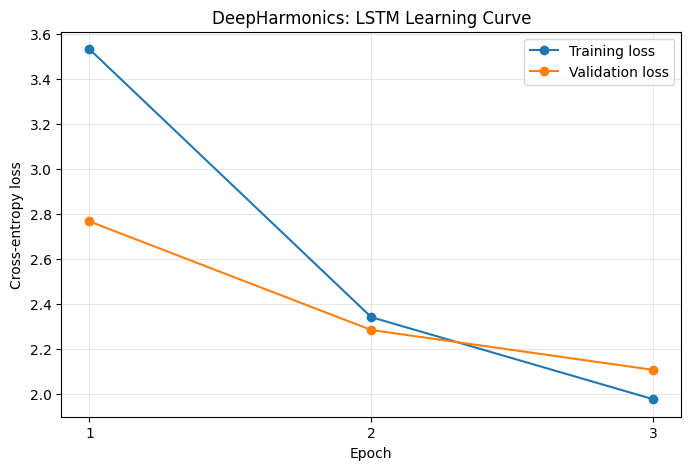

Epoch history:
{'epoch': 1, 'train_loss': 3.5324854392044136, 'val_loss': 2.7668381357619847, 'val_accuracy': 0.3950332082009818, 'seconds': 263.89975929260254}
{'epoch': 2, 'train_loss': 2.3413081197226573, 'val_loss': 2.284247182884073, 'val_accuracy': 0.45394166907305805, 'seconds': 257.04950499534607}
{'epoch': 3, 'train_loss': 1.9764651125362949, 'val_loss': 2.106958564843121, 'val_accuracy': 0.47404706901530463, 'seconds': 256.84788751602173}


In [21]:

import matplotlib.pyplot as plt

epochs_seen = [row["epoch"] for row in history]
train_losses = [row["train_loss"] for row in history]
val_losses = [row["val_loss"] for row in history]

plt.figure(figsize=(8, 5))
plt.plot(epochs_seen, train_losses, marker="o", label="Training loss")
plt.plot(epochs_seen, val_losses, marker="o", label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("DeepHarmonics: LSTM Learning Curve")
plt.xticks(epochs_seen)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print("Epoch history:")
for row in history:
    print(row)

In [22]:

import torch
import torch.nn.functional as F
import numpy as np

# Use the first validation piece as a common starting context.
seed_piece_name = val_names[0]
seed_ids = encode_piece(seed_piece_name)

assert len(seed_ids) >= SEQUENCE_LENGTH, "Seed piece is too short."

seed_context = seed_ids[:SEQUENCE_LENGTH].tolist()

GENERATION_LENGTH = 256
TEMPERATURE = 0.8
TOP_K = 10
TOP_P = 0.90

def choose_next_token(logits, strategy, temperature=1.0,
                      top_k=10, top_p=0.90):
    logits = logits.clone()

    if strategy == "greedy":
        return int(torch.argmax(logits).item())

    # Temperature changes the sharpness of the probability distribution.
    logits = logits / max(temperature, 1e-5)

    if strategy == "top_k":
        k = min(top_k, logits.numel())
        values, indices = torch.topk(logits, k)
        filtered = torch.full_like(logits, float("-inf"))
        filtered[indices] = values
        logits = filtered

    elif strategy == "nucleus":
        sorted_logits, sorted_indices = torch.sort(
            logits, descending=True
        )
        sorted_probs = F.softmax(sorted_logits, dim=-1)
        cumulative_probs = torch.cumsum(sorted_probs, dim=-1)

        # Remove tokens after the cumulative probability crosses top_p.
        remove = cumulative_probs > top_p
        remove[1:] = remove[:-1].clone()
        remove[0] = False

        filtered = torch.full_like(logits, float("-inf"))
        kept_indices = sorted_indices[~remove]
        filtered[kept_indices] = logits[kept_indices]
        logits = filtered

    elif strategy != "temperature":
        raise ValueError(f"Unknown strategy: {strategy}")

    probabilities = F.softmax(logits, dim=-1)
    return int(torch.multinomial(probabilities, num_samples=1).item())


def generate_events(strategy, seed, length=GENERATION_LENGTH,
                    temperature=TEMPERATURE, top_k=TOP_K, top_p=TOP_P,
                    random_seed=42):
    torch.manual_seed(random_seed)
    model.eval()

    context = list(seed)
    generated = []

    with torch.no_grad():
        for _ in range(length):
            input_ids = torch.tensor(
                context[-SEQUENCE_LENGTH:],
                dtype=torch.long
            ).unsqueeze(0).to(device)

            logits = model(input_ids)[0]
            next_id = choose_next_token(
                logits,
                strategy=strategy,
                temperature=temperature,
                top_k=top_k,
                top_p=top_p
            )

            generated.append(next_id)
            context.append(next_id)

    return generated


sampling_strategies = {
    "greedy": {"strategy": "greedy", "random_seed": 42},
    "temperature": {
        "strategy": "temperature", "temperature": 0.8,
        "random_seed": 43
    },
    "top_k": {
        "strategy": "top_k", "temperature": 0.8,
        "top_k": 10, "random_seed": 44
    },
    "nucleus": {
        "strategy": "nucleus", "temperature": 0.8,
        "top_p": 0.90, "random_seed": 45
    }
}

generated_ids = {}

for name, settings in sampling_strategies.items():
    generated_ids[name] = generate_events(
        strategy=settings["strategy"],
        seed=seed_context,
        random_seed=settings["random_seed"],
        temperature=settings.get("temperature", 1.0),
        top_k=settings.get("top_k", TOP_K),
        top_p=settings.get("top_p", TOP_P)
    )
    print(f"{name}: generated {len(generated_ids[name])} events")

print("\nSeed piece:", seed_piece_name)
print("Generation length per strategy:", GENERATION_LENGTH)

greedy: generated 256 events
temperature: generated 256 events
top_k: generated 256 events
nucleus: generated 256 events

Seed piece: reelsr-t47.mid
Generation length per strategy: 256


In [23]:

from collections import Counter

def ids_to_valid_events(token_ids):
    valid_events = []

    for token_id in token_ids:
        event = vocab_events[token_id] if token_id < len(vocab_events) else UNK

        # Ignore unknown tokens when calculating musical event metrics.
        if event == UNK or not isinstance(event[0], (int, np.integer)):
            continue

        valid_events.append(event)

    return valid_events


def calculate_metrics(token_ids):
    events = ids_to_valid_events(token_ids)

    if not events:
        return {
            "valid_events": 0,
            "unknown_events": len(token_ids),
            "unique_pitches": 0,
            "pitch_diversity": 0.0,
            "immediate_repeat_rate": 0.0,
            "most_common_event_share": 0.0
        }

    pitches = [event[1] for event in events]
    counts = Counter(events)

    immediate_repeats = sum(
        events[i] == events[i - 1]
        for i in range(1, len(events))
    )

    return {
        "valid_events": len(events),
        "unknown_events": len(token_ids) - len(events),
        "unique_pitches": len(set(pitches)),
        "pitch_diversity": len(set(pitches)) / len(events),
        "immediate_repeat_rate": (
            immediate_repeats / (len(events) - 1)
            if len(events) > 1 else 0.0
        ),
        "most_common_event_share": max(counts.values()) / len(events)
    }


metrics = {
    name: calculate_metrics(ids)
    for name, ids in generated_ids.items()
}

for name, result in metrics.items():
    print(f"\n{name.upper()}")
    for metric_name, value in result.items():
        if isinstance(value, float):
            print(f"  {metric_name}: {value:.4f}")
        else:
            print(f"  {metric_name}: {value}")


GREEDY
  valid_events: 256
  unknown_events: 0
  unique_pitches: 13
  pitch_diversity: 0.0508
  immediate_repeat_rate: 0.0000
  most_common_event_share: 0.3789

TEMPERATURE
  valid_events: 256
  unknown_events: 0
  unique_pitches: 28
  pitch_diversity: 0.1094
  immediate_repeat_rate: 0.0275
  most_common_event_share: 0.0859

TOP_K
  valid_events: 256
  unknown_events: 0
  unique_pitches: 23
  pitch_diversity: 0.0898
  immediate_repeat_rate: 0.0353
  most_common_event_share: 0.1133

NUCLEUS
  valid_events: 256
  unknown_events: 0
  unique_pitches: 24
  pitch_diversity: 0.0938
  immediate_repeat_rate: 0.0667
  most_common_event_share: 0.0977


In [24]:

import os
import pretty_midi

OUTPUT_DIR = "/content/deepharmonics_generated"
os.makedirs(OUTPUT_DIR, exist_ok=True)

def bin_to_representative_value(bin_id, edges):
    """
    np.digitize returns:
    0 for values below the first edge,
    1..len(edges)-1 for interior bins,
    len(edges) for values at or above the final edge.
    """
    if bin_id == 0:
        return edges[0] / 2

    if bin_id >= len(edges):
        return edges[-1] + (edges[-1] - edges[-2]) / 2

    lower = edges[bin_id - 1]
    upper = edges[bin_id]
    return (lower + upper) / 2


def events_to_midi(token_ids, output_path):
    events = ids_to_valid_events(token_ids)

    midi = pretty_midi.PrettyMIDI(initial_tempo=120)
    instruments = {}

    current_start = 0.0

    for part, pitch, duration_bin, gap_bin in events:
        gap = bin_to_representative_value(gap_bin, GAP_BINS)
        duration = bin_to_representative_value(
            duration_bin, DURATION_BINS
        )

        # Reconstruct onsets by accumulating the predicted start gaps.
        current_start += gap

        if part not in instruments:
            instruments[part] = pretty_midi.Instrument(
                program=0,
                name=f"Generated part {part}"
            )
            midi.instruments.append(instruments[part])

        note_start = current_start
        note_end = note_start + max(duration, 0.05)

        instruments[part].notes.append(
            pretty_midi.Note(
                velocity=90,
                pitch=int(np.clip(pitch, 0, 127)),
                start=note_start,
                end=note_end
            )
        )

    midi.write(output_path)
    return len(events)


for name, ids in generated_ids.items():
    output_path = os.path.join(
        OUTPUT_DIR, f"deepharmonics_{name}.mid"
    )
    note_count = events_to_midi(ids, output_path)
    print(f"{name}: saved {output_path} ({note_count} valid events)")

greedy: saved /content/deepharmonics_generated/deepharmonics_greedy.mid (256 valid events)
temperature: saved /content/deepharmonics_generated/deepharmonics_temperature.mid (256 valid events)
top_k: saved /content/deepharmonics_generated/deepharmonics_top_k.mid (256 valid events)
nucleus: saved /content/deepharmonics_generated/deepharmonics_nucleus.mid (256 valid events)


In [25]:

import pandas as pd
import numpy as np

# Choose five validation pieces with enough events for a 64-event seed.
eligible_pieces = [
    name for name in val_names
    if len(events_by_file[name]) >= SEQUENCE_LENGTH
]

N_PIECES = min(5, len(eligible_pieces))
selected_pieces = eligible_pieces[:N_PIECES]

strategies = ["greedy", "temperature", "top_k", "nucleus"]
experiment_rows = []

strategy_parameters = {
    "greedy": {},
    "temperature": {"temperature": 0.8},
    "top_k": {"temperature": 0.8, "top_k": 10},
    "nucleus": {"temperature": 0.8, "top_p": 0.90}
}

for piece_index, piece_name in enumerate(selected_pieces):
    piece_ids = encode_piece(piece_name)
    seed = piece_ids[:SEQUENCE_LENGTH].tolist()

    print(f"Processing piece {piece_index + 1}/{N_PIECES}: {piece_name}")

    for strategy_index, strategy in enumerate(strategies):
        random_seed = 1000 + piece_index * 10 + strategy_index

        generated = generate_events(
            strategy=strategy,
            seed=seed,
            length=GENERATION_LENGTH,
            random_seed=random_seed,
            **strategy_parameters[strategy]
        )

        row = {
            "piece": piece_name,
            "strategy": strategy,
            **calculate_metrics(generated)
        }
        experiment_rows.append(row)

results_df = pd.DataFrame(experiment_rows)

print("\nIndividual sample results:")
display(results_df.round(4))

summary_df = (
    results_df
    .groupby("strategy")[
        [
            "unique_pitches",
            "pitch_diversity",
            "immediate_repeat_rate",
            "most_common_event_share"
        ]
    ]
    .agg(["mean", "std"])
    .round(4)
)

print("\nMean and standard deviation across pieces:")
display(summary_df)

results_df.to_csv(
    "/content/deepharmonics_sampling_results.csv",
    index=False
)
print("Saved results to /content/deepharmonics_sampling_results.csv")

Processing piece 1/5: reelsr-t47.mid
Processing piece 2/5: waltzes51.mid
Processing piece 3/5: reelsu-z19.mid
Processing piece 4/5: reelsr-t12.mid
Processing piece 5/5: reelsd-g79.mid

Individual sample results:


,piece,strategy,valid_events,unknown_events,unique_pitches,pitch_diversity,immediate_repeat_rate,most_common_event_share
0,reelsr-t47.mid,greedy,256,0,13,0.0508,0.0000,0.3789
1,reelsr-t47.mid,temperature,256,0,27,0.1055,0.0392,0.1094
2,reelsr-t47.mid,top_k,256,0,27,0.1055,0.0431,0.0898
3,reelsr-t47.mid,nucleus,256,0,24,0.0938,0.0353,0.0859
4,waltzes51.mid,greedy,256,0,15,0.0586,0.0157,0.1719
5,waltzes51.mid,temperature,256,0,24,0.0938,0.0000,0.0898
6,waltzes51.mid,top_k,256,0,21,0.0820,0.0275,0.0586
7,waltzes51.mid,nucleus,256,0,24,0.0938,0.0235,0.0781
8,reelsu-z19.mid,greedy,256,0,11,0.0430,0.3647,0.4883
9,reelsu-z19.mid,temperature,256,0,26,0.1016,0.0510,0.0547



Mean and standard deviation across pieces:


unique_pitches         pitch_diversity          \
                      mean     std            mean     std   
strategy                                                     
greedy                11.6  5.8138          0.0453  0.0227   
nucleus               23.4  2.8810          0.0914  0.0113   
temperature           25.8  1.7889          0.1008  0.0070   
top_k                 23.4  2.6077          0.0914  0.0102   

            immediate_repeat_rate         most_common_event_share          
                             mean     std                    mean     std  
strategy                                                                   
greedy                     0.0761  0.1615                  0.3508  0.1520  
nucleus                    0.0337  0.0240                  0.0867  0.0268  
temperature                0.0259  0.0199                  0.0797  0.0208  
top_k                      0.0298  0.0081                  0.0898  0.0239

Saved results to /content/deepharmonics_sampling_results.csv


In [26]:

import pandas as pd

results_df = pd.read_csv(
    "/content/deepharmonics_sampling_results.csv"
)

metric_columns = [
    "unique_pitches",
    "pitch_diversity",
    "immediate_repeat_rate",
    "most_common_event_share"
]

verified_summary = (
    results_df.groupby("strategy")[metric_columns]
    .agg(["mean", "std"])
    .round(4)
)

display(verified_summary)

print("Samples per strategy:")
print(results_df.groupby("strategy").size())

print("\nPieces per strategy:")
print(results_df.groupby("strategy")["piece"].nunique())

unique_pitches         pitch_diversity          \
                      mean     std            mean     std   
strategy                                                     
greedy                11.6  5.8138          0.0453  0.0227   
nucleus               23.4  2.8810          0.0914  0.0113   
temperature           25.8  1.7889          0.1008  0.0070   
top_k                 23.4  2.6077          0.0914  0.0102   

            immediate_repeat_rate         most_common_event_share          
                             mean     std                    mean     std  
strategy                                                                   
greedy                     0.0761  0.1615                  0.3508  0.1520  
nucleus                    0.0337  0.0240                  0.0867  0.0268  
temperature                0.0259  0.0199                  0.0797  0.0208  
top_k                      0.0298  0.0081                  0.0898  0.0239

Samples per strategy:
strategy
greedy         5
nucleus        5
temperature    5
top_k          5
dtype: int64

Pieces per strategy:
strategy
greedy         5
nucleus        5
temperature    5
top_k          5
Name: piece, dtype: int64


In [27]:

from IPython.display import Audio, display
import pretty_midi
import os

OUTPUT_DIR = "/content/deepharmonics_generated"

midi_files = {
    "Greedy": "deepharmonics_greedy.mid",
    "Temperature": "deepharmonics_temperature.mid",
    "Top-k": "deepharmonics_top_k.mid",
    "Nucleus": "deepharmonics_nucleus.mid"
}

for name, filename in midi_files.items():
    path = os.path.join(OUTPUT_DIR, filename)

    midi = pretty_midi.PrettyMIDI(path)

    # Convert MIDI notes into audio that Colab can play.
    audio = midi.fluidsynth()

    print(f"{name} sampling")
    display(Audio(audio, rate=44100))

ImportError: fluidsynth() was called but pyfluidsynth is not installed.

In [28]:

!apt-get -qq update
!apt-get -qq install -y fluidsynth
!pip -q install pyfluidsynth

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Extracting templates from packages: 100%
Selecting previously unselected package libevdev2:amd64.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../00-libevdev2_1.13.1+dfsg-1build1_amd64.deb ...
Unpacking libevdev2:amd64 (1.13.1+dfsg-1build1) ...
Selecting previously unselected package at-spi2-common.
Preparing to unpack .../01-at-spi2-common_2.52.0-1build1_all.deb ...
Unpacking at-spi2-common (2.52.0-1build1) ...
Selecting previously unselected package libatspi2.0-0t64:amd64.
Preparing to unpack .../02-libatspi2.0-0t64_2.52.0-1build1_amd64.deb ...
Unpacking libatspi2.0-0t64:amd64 (2.52.0-1build1) ...
Selecting previously unselected package libxtst6:amd64.
Preparing to unpack .../03-libxtst6_2%3a1.2.3-1.1build1_amd64.deb ...
Unpacking libxtst6:amd64 (2:1

In [29]:

from IPython.display import Audio, display
import pretty_midi
import os

OUTPUT_DIR = "/content/deepharmonics_generated"

midi_files = {
    "Greedy": "deepharmonics_greedy.mid",
    "Temperature": "deepharmonics_temperature.mid",
    "Top-k": "deepharmonics_top_k.mid",
    "Nucleus": "deepharmonics_nucleus.mid"
}

for name, filename in midi_files.items():
    path = os.path.join(OUTPUT_DIR, filename)

    midi = pretty_midi.PrettyMIDI(path)
    audio = midi.fluidsynth(fs=44100)

    print(f"🎵 {name} sampling")
    display(Audio(audio, rate=44100))

ImportError: fluidsynth() was called but pyfluidsynth is not installed.

In [30]:

%pip install --upgrade pyfluidsynth

In [31]:

import fluidsynth
import pretty_midi

print("pyfluidsynth imported successfully!")
print("pretty_midi version:", pretty_midi.__version__)

pyfluidsynth imported successfully!
pretty_midi version: 0.2.11.post0


In [32]:

import sys
import subprocess
import importlib.util

print("Python:", sys.executable)
print("pyfluidsynth detected:", importlib.util.find_spec("fluidsynth"))

subprocess.run([
    sys.executable, "-m", "pip", "show", "pyfluidsynth"
])

Python: /usr/bin/python3
pyfluidsynth detected: ModuleSpec(name='fluidsynth', loader=<_frozen_importlib_external.SourceFileLoader object at 0x7d832457fe30>, origin='/usr/local/lib/python3.13/dist-packages/fluidsynth.py')


CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'show', 'pyfluidsynth'], returncode=0)

In [33]:

from IPython.display import Audio, display
import pretty_midi
import os

OUTPUT_DIR = "/content/deepharmonics_generated"

midi_files = {
    "Greedy": "deepharmonics_greedy.mid",
    "Temperature": "deepharmonics_temperature.mid",
    "Top-k": "deepharmonics_top_k.mid",
    "Nucleus": "deepharmonics_nucleus.mid"
}

for name, filename in midi_files.items():
    path = os.path.join(OUTPUT_DIR, filename)

    midi = pretty_midi.PrettyMIDI(path)
    audio = midi.fluidsynth(fs=44100)

    print(f"🎵 {name} sampling")
    display(Audio(audio, rate=44100))

ImportError: fluidsynth() was called but pyfluidsynth is not installed.

In [34]:

import os
import zipfile
from google.colab import files

OUTPUT_DIR = "/content/deepharmonics_generated"
ZIP_PATH = "/content/deepharmonics_midi_samples.zip"

filenames = [
    "deepharmonics_greedy.mid",
    "deepharmonics_temperature.mid",
    "deepharmonics_top_k.mid",
    "deepharmonics_nucleus.mid",
]

with zipfile.ZipFile(ZIP_PATH, "w") as z:
    for filename in filenames:
        path = os.path.join(OUTPUT_DIR, filename)
        if os.path.exists(path):
            z.write(path, arcname=filename)
            print("Added:", filename)
        else:
            print("Missing:", path)

files.download(ZIP_PATH)

Added: deepharmonics_greedy.mid
Added: deepharmonics_temperature.mid
Added: deepharmonics_top_k.mid
Added: deepharmonics_nucleus.mid


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [35]:

import pretty_midi
import os
import numpy as np

OUTPUT_DIR = "/content/deepharmonics_generated"
filename = "deepharmonics_top_k.mid"
path = os.path.join(OUTPUT_DIR, filename)

midi = pretty_midi.PrettyMIDI(path)

print("File:", filename)
print("Number of tracks:", len(midi.instruments))
print("Total duration:", round(midi.get_end_time(), 2), "seconds")

for i, instrument in enumerate(midi.instruments):
    notes = instrument.notes

    if not notes:
        print(f"\nTrack {i}: no notes")
        continue

    starts = np.array([n.start for n in notes])
    ends = np.array([n.end for n in notes])
    pitches = np.array([n.pitch for n in notes])

    # Count notes that begin before the previous note ends,
    # after sorting notes by their start times.
    order = np.argsort(starts)
    sorted_starts = starts[order]
    sorted_ends = ends[order]

    overlaps_previous = np.sum(
        sorted_starts[1:] < sorted_ends[:-1]
    )

    print(f"\nTrack {i}")
    print("  Program:", instrument.program)
    print("  Note count:", len(notes))
    print("  Pitch range:", int(pitches.min()), "-", int(pitches.max()))
    print("  Average note duration:", round(float(np.mean(ends - starts)), 3), "s")
    print("  Notes overlapping the previous note:", int(overlaps_previous))
    print("  First 10 pitches:", pitches[:10].tolist())

File: deepharmonics_top_k.mid
Number of tracks: 2
Total duration: 67.91 seconds

Track 0
  Program: 0
  Note count: 105
  Pitch range: 38 - 55
  Average note duration: 1.667 s
  Notes overlapping the previous note: 77
  First 10 pitches: [38, 42, 45, 38, 42, 45, 38, 42, 45, 43]

Track 1
  Program: 0
  Note count: 151
  Pitch range: 62 - 79
  Average note duration: 0.35 s
  Notes overlapping the previous note: 0
  First 10 pitches: [66, 69, 71, 69, 74, 74, 69, 74, 73, 74]


In [36]:

import pretty_midi
import os

path = "/content/deepharmonics_generated/deepharmonics_top_k.mid"
midi = pretty_midi.PrettyMIDI(path)

for track_idx, instrument in enumerate(midi.instruments):
    print(f"\n{'=' * 55}")
    print(f"TRACK {track_idx}")
    print(f"{'=' * 55}")

    notes = sorted(instrument.notes, key=lambda n: n.start)

    print(f"{'Pitch':<8}{'Start (s)':<14}{'End (s)':<14}{'Duration (s)':<14}")

    for note in notes[:20]:
        print(
            f"{note.pitch:<8}"
            f"{note.start:<14.3f}"
            f"{note.end:<14.3f}"
            f"{note.end - note.start:<14.3f}"
        )


TRACK 0
Pitch   Start (s)     End (s)       Duration (s)  
38      0.032         2.532         2.500         
42      0.064         2.564         2.500         
45      0.093         2.593         2.500         
38      3.500         6.000         2.500         
42      3.532         6.032         2.500         
45      3.564         6.064         2.500         
38      6.968         9.468         2.500         
42      7.000         9.500         2.500         
45      7.032         9.532         2.500         
43      10.436        11.686        1.250         
47      10.468        11.718        1.250         
50      10.500        11.750        1.250         
45      12.032        13.282        1.250         
49      12.064        13.314        1.250         
52      12.093        13.343        1.250         
55      12.125        13.375        1.250         
45      13.282        14.532        1.250         
49      13.314        14.564        1.250         
52      13.343        

In [37]:

import pretty_midi
import numpy as np

path = "/content/deepharmonics_generated/deepharmonics_top_k.mid"
midi = pretty_midi.PrettyMIDI(path)

track0 = midi.instruments[0].notes
track1 = midi.instruments[1].notes

# Duration distribution for each track
for i, notes in enumerate([track0, track1]):
    durations = np.array([n.end - n.start for n in notes])

    print(f"\nTrack {i}")
    print("Note count:", len(notes))
    print("Minimum duration:", round(float(durations.min()), 3))
    print("Median duration:", round(float(np.median(durations)), 3))
    print("Maximum duration:", round(float(durations.max()), 3))
    print("Notes lasting >= 1 second:", int(np.sum(durations >= 1.0)))

# Count cross-track note pairs that overlap in time
cross_track_overlaps = 0

for low_note in track0:
    for high_note in track1:
        if low_note.start < high_note.end and high_note.start < low_note.end:
            cross_track_overlaps += 1

print("\nCross-track overlapping note pairs:", cross_track_overlaps)


Track 0
Note count: 105
Minimum duration: 1.25
Median duration: 1.25
Maximum duration: 2.5
Notes lasting >= 1 second: 105

Track 1
Note count: 151
Minimum duration: 0.311
Median duration: 0.314
Maximum duration: 0.627
Notes lasting >= 1 second: 0

Cross-track overlapping note pairs: 463


In [38]:
duration = ...
gap = ...
start = ...
end = ...

In [39]:

import os
import pretty_midi
import numpy as np

TEST_OUTPUT_DIR = "/content/deepharmonics_duration_test"
os.makedirs(TEST_OUTPUT_DIR, exist_ok=True)

def events_to_midi_duration_test(token_ids, output_path):
    events = ids_to_valid_events(token_ids)

    midi = pretty_midi.PrettyMIDI(initial_tempo=120)
    instruments = {}
    current_start = 0.0

    for part, pitch, duration_bin, gap_bin in events:
        gap = bin_to_representative_value(gap_bin, GAP_BINS)
        duration = bin_to_representative_value(
            duration_bin, DURATION_BINS
        )

        current_start += gap

        if part not in instruments:
            instruments[part] = pretty_midi.Instrument(
                program=0,
                name=f"Generated part {part}"
            )
            midi.instruments.append(instruments[part])

        # Diagnostic experiment: limit note duration to 0.75 seconds.
        duration = min(max(duration, 0.05), 0.75)

        instruments[part].notes.append(
            pretty_midi.Note(
                velocity=90,
                pitch=int(np.clip(pitch, 0, 127)),
                start=current_start,
                end=current_start + duration
            )
        )

    midi.write(output_path)
    return len(events)


output_path = os.path.join(
    TEST_OUTPUT_DIR, "deepharmonics_top_k_short_notes.mid"
)

note_count = events_to_midi_duration_test(
    generated_ids["top_k"],
    output_path
)

print("Saved diagnostic MIDI:", output_path)
print("Events:", note_count)

Saved diagnostic MIDI: /content/deepharmonics_duration_test/deepharmonics_top_k_short_notes.mid
Events: 256


In [40]:

from google.colab import files
files.download(
    "/content/deepharmonics_duration_test/deepharmonics_top_k_short_notes.mid"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [41]:

import pretty_midi
import numpy as np
import os

path = os.path.join(DATA_DIR, "reelsr-t47.mid")
original = pretty_midi.PrettyMIDI(path)

for i, instrument in enumerate(original.instruments):
    notes = instrument.notes

    if not notes:
        continue

    durations = np.array([n.end - n.start for n in notes])

    print(f"\nTrack {i}: {instrument.name or 'Unnamed'}")
    print("Notes:", len(notes))
    print("Median duration:", round(float(np.median(durations)), 3), "s")
    print("Mean duration:", round(float(np.mean(durations)), 3), "s")
    print("Duration >= 1 second:", int(np.sum(durations >= 1.0)))


Track 0: Unnamed
Notes: 225
Median duration: 0.25 s
Mean duration: 0.427 s
Duration >= 1 second: 19

Track 1: Unnamed
Notes: 227
Median duration: 1.0 s
Mean duration: 1.344 s
Duration >= 1 second: 227


/usr/local/lib/python3.13/dist-packages/pretty_midi/pretty_midi.py:122: RuntimeWarning: Tempo, Key or Time signature change events found on non-zero tracks.  This is not a valid type 0 or type 1 MIDI file.  Tempo, Key or Time Signature may be wrong.
  warnings.warn(


In [42]:

from collections import Counter

events = ids_to_valid_events(generated_ids["top_k"])

for part in sorted(set(event[0] for event in events)):
    part_events = [event for event in events if event[0] == part]

    duration_counts = Counter(event[2] for event in part_events)

    print(f"\nPart {part}: {len(part_events)} events")
    print("Duration-bin counts:", dict(sorted(duration_counts.items())))

    for bin_id, count in sorted(duration_counts.items()):
        seconds = bin_to_representative_value(
            bin_id, DURATION_BINS
        )
        print(f"  Bin {bin_id}: {seconds:.3f} seconds ({count} events)")


Part 0: 151 events
Duration-bin counts: {2: 133, 4: 18}
  Bin 2: 0.312 seconds (133 events)
  Bin 4: 0.625 seconds (18 events)

Part 1: 105 events
Duration-bin counts: {6: 70, 8: 35}
  Bin 6: 1.250 seconds (70 events)
  Bin 8: 2.500 seconds (35 events)


In [43]:

from collections import Counter
import os
import pretty_midi
import numpy as np

filename = "reelsr-t47.mid"
path = os.path.join(DATA_DIR, filename)
midi = pretty_midi.PrettyMIDI(path)

for part_id, instrument in enumerate(midi.instruments):
    notes = instrument.notes

    if not notes:
        continue

    duration_bins = Counter(
        int(np.digitize(n.end - n.start, DURATION_BINS))
        for n in notes
    )

    print(f"\nOriginal Part {part_id}")
    print("Instrument:", instrument.name or "Unnamed")
    print("Notes:", len(notes))
    print("Duration-bin counts:", dict(sorted(duration_bins.items())))

    for bin_id, count in sorted(duration_bins.items()):
        representative = bin_to_representative_value(
            bin_id, DURATION_BINS
        )
        print(
            f"  Bin {bin_id}: {representative:.3f} seconds "
            f"({count} notes)"
        )


Original Part 0
Instrument: Unnamed
Notes: 225
Duration-bin counts: {2: 126, 4: 80, 6: 8, 7: 11}
  Bin 2: 0.312 seconds (126 notes)
  Bin 4: 0.625 seconds (80 notes)
  Bin 6: 1.250 seconds (8 notes)
  Bin 7: 1.750 seconds (11 notes)

Original Part 1
Instrument: Unnamed
Notes: 227
Duration-bin counts: {6: 149, 8: 78}
  Bin 6: 1.250 seconds (149 notes)
  Bin 8: 2.500 seconds (78 notes)


In [44]:

print("Checking DeepHarmonics experiment data...")

print("Model checkpoint exists:",
      os.path.exists("/content/deepharmonics_lstm_best.pt"))

print("Results CSV exists:",
      os.path.exists("/content/deepharmonics_sampling_results.csv"))

print("Results dataframe exists:",
      "results_df" in globals())

if "results_df" in globals():
    print("\nResults shape:", results_df.shape)
    print("\nAvailable columns:")
    print(results_df.columns.tolist())
    print("\nFirst five rows:")
    display(results_df.head())

Checking DeepHarmonics experiment data...
Model checkpoint exists: True
Results CSV exists: True
Results dataframe exists: True

Results shape: (20, 8)

Available columns:
['piece', 'strategy', 'valid_events', 'unknown_events', 'unique_pitches', 'pitch_diversity', 'immediate_repeat_rate', 'most_common_event_share']

First five rows:


,piece,strategy,valid_events,unknown_events,unique_pitches,pitch_diversity,immediate_repeat_rate,most_common_event_share
0,reelsr-t47.mid,greedy,256,0,13,0.050781,0.000000,0.378906
1,reelsr-t47.mid,temperature,256,0,27,0.105469,0.039216,0.109375
2,reelsr-t47.mid,top_k,256,0,27,0.105469,0.043137,0.089844
3,reelsr-t47.mid,nucleus,256,0,24,0.093750,0.035294,0.085938
4,waltzes51.mid,greedy,256,0,15,0.058594,0.015686,0.171875


In [45]:

print("=== VALIDATION DATA ===")

if "val_files" in globals():
    print("Validation pieces:", len(val_files))
    print("Example:", list(val_files)[:5])
elif "val_sequences" in globals():
    print("Validation sequences available:", len(val_sequences))
else:
    print("Could not find val_files or val_sequences.")

print("\n=== GENERATION SETUP ===")

for name in ["generated_ids", "model", "best_model",
             "val_to_ids", "ids_to_valid_events"]:
    print(f"{name} available:", name in globals())

print("\n=== SAVED RESULTS ===")

print("Existing samples:", len(results_df))
print("Strategies:", sorted(results_df["strategy"].unique()))
print("Pieces:", results_df["piece"].nunique())
print("Events per sample:", sorted(results_df["valid_events"].unique()))

=== VALIDATION DATA ===
Could not find val_files or val_sequences.

=== GENERATION SETUP ===
generated_ids available: True
model available: True
best_model available: False
val_to_ids available: False
ids_to_valid_events available: True

=== SAVED RESULTS ===
Existing samples: 20
Strategies: ['greedy', 'nucleus', 'temperature', 'top_k']
Pieces: 5
Events per sample: [np.int64(256)]


In [46]:

print("=== VARIABLES RELATED TO DATA ===")

for name in sorted(globals()):
    name_lower = name.lower()

    if any(word in name_lower for word in [
        "val", "valid", "test", "train",
        "sequence", "event", "midi", "file", "data"
    ]):
        obj = globals()[name]

        if not callable(obj):
            try:
                print(
                    f"{name}: type={type(obj).__name__}, "
                    f"length={len(obj)}"
                )
            except (TypeError, AttributeError):
                print(f"{name}: type={type(obj).__name__}")

=== VARIABLES RELATED TO DATA ===
DATA_DIR: type=str, length=32
SEQUENCE_LENGTH: type=int
TEST_OUTPUT_DIR: type=str, length=36
X_test: type=ndarray, length=29602
X_train: type=ndarray, length=232834
X_val: type=ndarray, length=27704
all_events: type=list, length=356269
best_val_loss: type=float
event: type=tuple, length=4
event_to_id: type=dict, length=978
events: type=list, length=256
events_by_file: type=dict, length=1034
failed_files: type=list, length=0
file_path: type=str, length=45
filename: type=str, length=14
filenames: type=list, length=4
files: type=module
files_with_warnings: type=list, length=1021
metadata_count: type=Counter, length=2
midi: type=PrettyMIDI
midi_data: type=PrettyMIDI
midi_dir: type=str, length=32
midi_files: type=dict, length=4
part_events: type=list, length=105
pitch_values: type=list, length=356269
pretty_midi: type=module
raw_midi: type=MidiFile
test_names: type=list, length=104
total_train_examples: type=int
total_train_loss: type=float
track_events: ty

In [47]:

print("=== VALIDATION FILES ===")
print("Number of validation files:", len(val_names))
print("First 10 validation filenames:")
print(list(val_names)[:10])

print("\n=== EVENT DATA FORMAT ===")
print("Number of files in events_by_file:", len(events_by_file))

first_file = next(iter(events_by_file))
print("Example filename:", first_file)
print("Stored data type:", type(events_by_file[first_file]).__name__)
print("First 3 stored events:", events_by_file[first_file][:3])

print("\n=== VALIDATION FILE LOOKUP ===")
for name in list(val_names)[:5]:
    print(
        repr(name),
        "direct match:", name in events_by_file
    )

=== VALIDATION FILES ===
Number of validation files: 103
First 10 validation filenames:
['reelsr-t47.mid', 'waltzes51.mid', 'reelsu-z19.mid', 'reelsr-t12.mid', 'reelsd-g79.mid', 'jigs274.mid', 'reelsd-g66.mid', 'hpps7.mid', 'reelsa-c3.mid', 'jigs163.mid']

=== EVENT DATA FORMAT ===
Number of files in events_by_file: 1034
Example filename: ashover1.mid
Stored data type: list
First 3 stored events: [(0, 76, 4, 5), (0, 74, 6, 4), (1, 43, 7, 0)]

=== VALIDATION FILE LOOKUP ===
'reelsr-t47.mid' direct match: True
'waltzes51.mid' direct match: True
'reelsu-z19.mid' direct match: True
'reelsr-t12.mid' direct match: True
'reelsd-g79.mid' direct match: True


In [48]:

import inspect

print("=== MODEL ===")
print("Model type:", type(model).__name__)
print("Model device:", next(model.parameters()).device)

print("\n=== MODEL FORWARD METHOD ===")
print(inspect.signature(model.forward))

print("\n=== EVENT ENCODING ===")
print("Vocabulary size:", len(event_to_id))
print("Sequence length:", SEQUENCE_LENGTH)
print("Unknown token ID:", event_to_id.get("UNK"))

print("\n=== EXISTING GENERATION VARIABLES ===")
print("generated_ids type:", type(generated_ids).__name__)

for key, value in generated_ids.items():
    print(
        f"{key}: type={type(value).__name__}, "
        f"length={len(value)}"
    )

=== MODEL ===
Model type: MusicLSTM
Model device: cpu

=== MODEL FORWARD METHOD ===
(x)

=== EVENT ENCODING ===
Vocabulary size: 978
Sequence length: 64
Unknown token ID: None

=== EXISTING GENERATION VARIABLES ===
generated_ids type: dict
greedy: type=list, length=256
temperature: type=list, length=256
top_k: type=list, length=256
nucleus: type=list, length=256


In [49]:

import inspect

print("=== GENERATION-RELATED FUNCTIONS ===")

for name, obj in sorted(globals().copy().items()):
    if callable(obj) and (
        "generat" in name.lower()
        or "sampl" in name.lower()
        or "predict" in name.lower()
    ):
        try:
            print(f"\n--- {name} ---")
            print(inspect.signature(obj))
            print(inspect.getsource(obj)[:3500])
        except (OSError, TypeError, ValueError):
            print("Source unavailable; signature shown if accessible.")

=== GENERATION-RELATED FUNCTIONS ===

--- generate_events ---
(strategy, seed, length=256, temperature=0.8, top_k=10, top_p=0.9, random_seed=42)
def generate_events(strategy, seed, length=GENERATION_LENGTH,
                    temperature=TEMPERATURE, top_k=TOP_K, top_p=TOP_P,
                    random_seed=42):
    torch.manual_seed(random_seed)
    model.eval()

    context = list(seed)
    generated = []

    with torch.no_grad():
        for _ in range(length):
            input_ids = torch.tensor(
                context[-SEQUENCE_LENGTH:],
                dtype=torch.long
            ).unsqueeze(0).to(device)

            logits = model(input_ids)[0]
            next_id = choose_next_token(
                logits,
                strategy=strategy,
                temperature=temperature,
                top_k=top_k,
                top_p=top_p
            )

            generated.append(next_id)
            context.append(next_id)

    return generated



In [50]:

import os
import random
import numpy as np
import pandas as pd

# Reproducible selection of 20 validation pieces
rng = random.Random(42)
candidate_names = sorted(set(val_names))

# Preserve the five pieces from the pilot experiment
pilot_pieces = list(results_df["piece"].unique())
remaining_pieces = [
    name for name in candidate_names
    if name not in pilot_pieces
]

if len(pilot_pieces) != 5:
    raise ValueError("Expected 5 pilot pieces; check results_df.")

rng.shuffle(remaining_pieces)
selected_pieces = pilot_pieces + remaining_pieces[:15]

# Confirm each selected piece has enough events for a 64-event seed
selected_pieces = [
    name for name in selected_pieces
    if name in events_by_file
    and len(events_by_file[name]) > SEQUENCE_LENGTH
]

print("Selected pieces:", len(selected_pieces))
print("Strategies: greedy, temperature, top_k, nucleus")
print("Expected new samples:", len(selected_pieces) * 4)
print("Existing results remain unchanged.")
print("\nSelected filenames:")
print(selected_pieces)

Selected pieces: 20
Strategies: greedy, temperature, top_k, nucleus
Expected new samples: 80
Existing results remain unchanged.

Selected filenames:
['reelsr-t47.mid', 'waltzes51.mid', 'reelsu-z19.mid', 'reelsr-t12.mid', 'reelsd-g79.mid', 'reelsr-t69.mid', 'reelsd-g8.mid', 'reelsh-l18.mid', 'jigs101.mid', 'jigs42.mid', 'jigs243.mid', 'ashover2.mid', 'reelsh-l8.mid', 'jigs144.mid', 'reelsd-g80.mid', 'reelsh-l40.mid', 'jigs104.mid', 'reelsa-c76.mid', 'reelsm-q29.mid', 'reelsa-c72.mid']


In [51]:

import os
import numpy as np
import pandas as pd
import torch

strategies = ["greedy", "temperature", "top_k", "nucleus"]
expanded_rows = []

# Use the same settings as the original pilot experiment
for piece_idx, piece in enumerate(selected_pieces):
    source_events = events_by_file[piece]

    # Convert source events to token IDs
    seed = [
        event_to_id[event]
        for event in source_events[:SEQUENCE_LENGTH]
        if event in event_to_id
    ]

    if len(seed) != SEQUENCE_LENGTH:
        print(f"Skipping {piece}: seed has {len(seed)} known tokens")
        continue

    for strategy in strategies:
        generated = generate_events(
            strategy=strategy,
            seed=seed,
            length=256,
            temperature=0.8,
            top_k=10,
            top_p=0.90,
            random_seed=42 + piece_idx
        )

        # Keep only IDs represented in the event vocabulary
        valid_events = [
            vocab_events[token_id]
            for token_id in generated
            if 0 <= token_id < len(vocab_events)
        ]

        pitches = [event[1] for event in valid_events]

        unique_pitches = len(set(pitches))
        pitch_diversity = (
            unique_pitches / len(valid_events)
            if valid_events else 0
        )

        repeat_rate = (
            sum(
                valid_events[i] == valid_events[i - 1]
                for i in range(1, len(valid_events))
            ) / (len(valid_events) - 1)
            if len(valid_events) > 1 else 0
        )

        counts = pd.Series(valid_events).value_counts()
        common_event_share = (
            counts.iloc[0] / len(valid_events)
            if len(valid_events) else 0
        )

        expanded_rows.append({
            "piece": piece,
            "strategy": strategy,
            "valid_events": len(valid_events),
            "unknown_events": len(generated) - len(valid_events),
            "unique_pitches": unique_pitches,
            "pitch_diversity": pitch_diversity,
            "immediate_repeat_rate": repeat_rate,
            "most_common_event_share": common_event_share
        })

    print(f"Completed {piece}")

expanded_df = pd.DataFrame(expanded_rows)

output_path = "/content/deepharmonics_sampling_results_expanded.csv"
expanded_df.to_csv(output_path, index=False)

print("\n=== EXPERIMENT SUMMARY ===")
print("Rows generated:", len(expanded_df))
print("Unique pieces:", expanded_df["piece"].nunique())
print("Strategies:", sorted(expanded_df["strategy"].unique()))
print("Saved to:", output_path)

display(expanded_df.head(8))

Completed reelsr-t47.mid
Completed waltzes51.mid
Completed reelsu-z19.mid
Completed reelsr-t12.mid
Completed reelsd-g79.mid
Completed reelsr-t69.mid
Completed reelsd-g8.mid
Completed reelsh-l18.mid
Completed jigs101.mid
Completed jigs42.mid
Completed jigs243.mid
Completed ashover2.mid
Completed reelsh-l8.mid
Completed jigs144.mid
Completed reelsd-g80.mid
Completed reelsh-l40.mid
Completed jigs104.mid
Completed reelsa-c76.mid
Skipping reelsm-q29.mid: seed has 63 known tokens
Completed reelsa-c72.mid

=== EXPERIMENT SUMMARY ===
Rows generated: 76
Unique pieces: 19
Strategies: ['greedy', 'nucleus', 'temperature', 'top_k']
Saved to: /content/deepharmonics_sampling_results_expanded.csv


,piece,strategy,valid_events,unknown_events,unique_pitches,pitch_diversity,immediate_repeat_rate,most_common_event_share
0,reelsr-t47.mid,greedy,256,0,13,0.050781,0.000000,0.378906
1,reelsr-t47.mid,temperature,256,0,26,0.101562,0.031373,0.070312
2,reelsr-t47.mid,top_k,256,0,24,0.093750,0.043137,0.085938
3,reelsr-t47.mid,nucleus,256,0,22,0.085938,0.054902,0.144531
4,waltzes51.mid,greedy,256,0,15,0.058594,0.015686,0.171875
5,waltzes51.mid,temperature,256,0,28,0.109375,0.011765,0.082031
6,waltzes51.mid,top_k,256,0,25,0.097656,0.015686,0.078125
7,waltzes51.mid,nucleus,256,0,22,0.085938,0.043137,0.082031


In [52]:

import pandas as pd
import numpy as np

# Reload the saved expanded results
expanded_df = pd.read_csv(
    "/content/deepharmonics_sampling_results_expanded.csv"
)

metrics = [
    "valid_events",
    "unknown_events",
    "unique_pitches",
    "pitch_diversity",
    "immediate_repeat_rate",
    "most_common_event_share"
]

summary = expanded_df.groupby("strategy")[metrics].agg(
    ["mean", "std"]
).round(4)

print("=== RESULTS BY SAMPLING STRATEGY ===")
display(summary)

print("\n=== EXPERIMENT VALIDATION ===")
print("Total rows:", len(expanded_df))
print("Unique pieces:", expanded_df["piece"].nunique())
print("\nSamples per strategy:")
display(expanded_df.groupby("strategy").size())

print("\nAll samples contain 256 events:",
      bool((expanded_df["valid_events"] == 256).all()))

print("All generated events are known:",
      bool((expanded_df["unknown_events"] == 0).all()))

print("\nPieces with all four strategies:")
strategy_counts = expanded_df.groupby("piece")["strategy"].nunique()
print(int((strategy_counts == 4).sum()))

=== RESULTS BY SAMPLING STRATEGY ===


valid_events      unknown_events      unique_pitches          \
                    mean  std           mean  std           mean     std   
strategy                                                                   
greedy             256.0  0.0            0.0  0.0        13.5263  3.5958   
nucleus            256.0  0.0            0.0  0.0        23.7368  2.1818   
temperature        256.0  0.0            0.0  0.0        25.7895  2.8398   
top_k              256.0  0.0            0.0  0.0        23.8947  2.4013   

            pitch_diversity         immediate_repeat_rate          \
                       mean     std                  mean     std   
strategy                                                            
greedy               0.0528  0.0140                0.0974  0.1478   
nucleus              0.0927  0.0085                0.0330  0.0162   
temperature          0.1007  0.0111                0.0287  0.0151   
top_k                0.0933  0.0094                0.0328  0.0222   

            most_common_event_share          
                               mean     std  
strategy                                     
greedy                       0.2660  0.1403  
nucleus                      0.0968  0.0213  
temperature                  0.0798  0.0159  
top_k                        0.0917  0.0200


=== EXPERIMENT VALIDATION ===
Total rows: 76
Unique pieces: 19

Samples per strategy:


,0
strategy,
greedy,19
nucleus,19
temperature,19
top_k,19



All samples contain 256 events: True
All generated events are known: True

Pieces with all four strategies:
19


In [53]:

import pandas as pd

df = pd.read_csv(
    "/content/deepharmonics_sampling_results_expanded.csv"
)

metrics = [
    "pitch_diversity",
    "immediate_repeat_rate",
    "most_common_event_share"
]

# One row per piece, with a separate column for each strategy
paired = {
    metric: df.pivot(
        index="piece",
        columns="strategy",
        values=metric
    )
    for metric in metrics
}

rows = []

for strategy in ["temperature", "top_k", "nucleus"]:
    for metric in metrics:
        differences = (
            paired[metric][strategy] - paired[metric]["greedy"]
        ).dropna()

        # Positive is better for diversity.
        # Negative is better for both repetition measures.
        higher_is_better = metric == "pitch_diversity"

        wins = (
            (differences > 0).sum()
            if higher_is_better
            else (differences < 0).sum()
        )

        rows.append({
            "strategy": strategy,
            "metric": metric,
            "mean_difference_vs_greedy": round(
                differences.mean(), 4
            ),
            "median_difference_vs_greedy": round(
                differences.median(), 4
            ),
            "pieces_better_than_greedy": int(wins),
            "pieces_compared": len(differences)
        })

paired_summary = pd.DataFrame(rows)

display(paired_summary)

,strategy,metric,mean_difference_vs_greedy,median_difference_vs_greedy,pieces_better_than_greedy,pieces_compared
0,temperature,pitch_diversity,0.0479,0.0469,19,19
1,temperature,immediate_repeat_rate,-0.0687,0.0118,8,19
2,temperature,most_common_event_share,-0.1863,-0.1523,19,19
3,top_k,pitch_diversity,0.0405,0.0430,19,19
4,top_k,immediate_repeat_rate,-0.0646,0.0078,7,19
5,top_k,most_common_event_share,-0.1743,-0.1641,18,19
6,nucleus,pitch_diversity,0.0399,0.0352,19,19
7,nucleus,immediate_repeat_rate,-0.0644,0.0118,6,19
8,nucleus,most_common_event_share,-0.1692,-0.1328,17,19


In [54]:

import pandas as pd

df = pd.read_csv(
    "/content/deepharmonics_sampling_results_expanded.csv"
)

repeat_pivot = df.pivot(
    index="piece",
    columns="strategy",
    values="immediate_repeat_rate"
)

for strategy in ["temperature", "top_k", "nucleus"]:
    diff = repeat_pivot[strategy] - repeat_pivot["greedy"]

    print(f"\n=== {strategy.upper()} vs GREEDY ===")
    print("Pieces with lower repeat rate:", int((diff < 0).sum()))
    print("Pieces with equal repeat rate:", int((diff == 0).sum()))
    print("Pieces with higher repeat rate:", int((diff > 0).sum()))
    print("Mean difference:", round(diff.mean(), 4))
    print("Median difference:", round(diff.median(), 4))


=== TEMPERATURE vs GREEDY ===
Pieces with lower repeat rate: 8
Pieces with equal repeat rate: 1
Pieces with higher repeat rate: 10
Mean difference: -0.0687
Median difference: 0.0118

=== TOP_K vs GREEDY ===
Pieces with lower repeat rate: 7
Pieces with equal repeat rate: 2
Pieces with higher repeat rate: 10
Mean difference: -0.0646
Median difference: 0.0078

=== NUCLEUS vs GREEDY ===
Pieces with lower repeat rate: 6
Pieces with equal repeat rate: 1
Pieces with higher repeat rate: 12
Mean difference: -0.0644
Median difference: 0.0118


In [55]:

import pandas as pd
import numpy as np

df = pd.read_csv(
    "/content/deepharmonics_sampling_results_expanded.csv"
)

print("=== SOURCE EVENT DISTRIBUTION ===")

source_rows = []

for piece in df["piece"].unique():
    events = events_by_file[piece]

    for part, pitch, duration_bin, gap_bin in events:
        source_rows.append({
            "piece": piece,
            "part": part,
            "pitch": pitch,
            "duration_bin": duration_bin,
            "gap_bin": gap_bin
        })

source_df = pd.DataFrame(source_rows)

print("Source events from evaluated pieces:", len(source_df))
print("Unique source pitches:", source_df["pitch"].nunique())
print("Source pitch range:",
      int(source_df["pitch"].min()),
      "to",
      int(source_df["pitch"].max()))

print("\nDuration-bin distribution:")
display(
    source_df["duration_bin"]
    .value_counts(normalize=True)
    .sort_index()
    .rename("proportion")
    .to_frame()
)

print("\nGap-bin distribution:")
display(
    source_df["gap_bin"]
    .value_counts(normalize=True)
    .sort_index()
    .rename("proportion")
    .to_frame()
)

=== SOURCE EVENT DISTRIBUTION ===
Source events from evaluated pieces: 6823
Unique source pitches: 39
Source pitch range: 36 to 85

Duration-bin distribution:


,proportion
duration_bin,
1,0.029606
2,0.366701
3,0.009673
4,0.128243
5,0.067272
6,0.219112
7,0.071083
8,0.102594
9,0.002198



Gap-bin distribution:


,proportion
gap_bin,
0,0.447311
2,0.029606
3,0.376227
4,0.134252
5,0.012604


In [56]:

import pandas as pd
import numpy as np

strategies = ["greedy", "temperature", "top_k", "nucleus"]
distribution_rows = []

# Use the same 19 pieces that were successfully evaluated
evaluated_pieces = expanded_df["piece"].drop_duplicates().tolist()

for piece_idx, piece in enumerate(selected_pieces):
    if piece not in evaluated_pieces:
        continue

    source_events = events_by_file[piece]
    seed = [
        event_to_id[event]
        for event in source_events[:SEQUENCE_LENGTH]
        if event in event_to_id
    ]

    if len(seed) != SEQUENCE_LENGTH:
        print("Skipping incomplete seed:", piece)
        continue

    for strategy in strategies:
        generated = generate_events(
            strategy=strategy,
            seed=seed,
            length=256,
            temperature=0.8,
            top_k=10,
            top_p=0.90,
            random_seed=42 + piece_idx
        )

        valid_events = [
            vocab_events[token_id]
            for token_id in generated
            if 0 <= token_id < len(vocab_events)
        ]

        for part, pitch, duration_bin, gap_bin in valid_events:
            distribution_rows.append({
                "piece": piece,
                "strategy": strategy,
                "pitch": pitch,
                "duration_bin": duration_bin,
                "gap_bin": gap_bin
            })

generated_dist_df = pd.DataFrame(distribution_rows)

# Source baseline, restricted to the same evaluated pieces
source_rows = []

for piece in evaluated_pieces:
    for part, pitch, duration_bin, gap_bin in events_by_file[piece]:
        source_rows.append({
            "piece": piece,
            "pitch": pitch,
            "duration_bin": duration_bin,
            "gap_bin": gap_bin
        })

source_eval_df = pd.DataFrame(source_rows)

print("Generated events:", len(generated_dist_df))
print("Evaluated pieces:", generated_dist_df["piece"].nunique())

print("\n=== DURATION-BIN PROPORTIONS ===")
duration_comparison = pd.DataFrame({
    "source": source_eval_df["duration_bin"].value_counts(
        normalize=True
    ),
    **{
        strategy: generated_dist_df.loc[
            generated_dist_df["strategy"] == strategy,
            "duration_bin"
        ].value_counts(normalize=True)
        for strategy in strategies
    }
}).fillna(0).sort_index().round(4)

display(duration_comparison)

print("\n=== GAP-BIN PROPORTIONS ===")
gap_comparison = pd.DataFrame({
    "source": source_eval_df["gap_bin"].value_counts(
        normalize=True
    ),
    **{
        strategy: generated_dist_df.loc[
            generated_dist_df["strategy"] == strategy,
            "gap_bin"
        ].value_counts(normalize=True)
        for strategy in strategies
    }
}).fillna(0).sort_index().round(4)

display(gap_comparison)

Generated events: 19456
Evaluated pieces: 19

=== DURATION-BIN PROPORTIONS ===


,source,greedy,temperature,top_k,nucleus
duration_bin,,,,,
0,0.0000,0.0000,0.0002,0.0000,0.0000
1,0.0296,0.0000,0.0189,0.0271,0.0004
2,0.3667,0.3592,0.3181,0.3563,0.4003
3,0.0097,0.0000,0.0012,0.0002,0.0000
4,0.1282,0.2015,0.1972,0.1622,0.1435
5,0.0673,0.1065,0.0866,0.0997,0.1112
6,0.2191,0.1211,0.1460,0.1782,0.1521
7,0.0711,0.0660,0.0565,0.0520,0.0454
8,0.1026,0.1458,0.1686,0.1221,0.1458



=== GAP-BIN PROPORTIONS ===


,source,greedy,temperature,top_k,nucleus
gap_bin,,,,,
0,0.4473,0.4377,0.4574,0.4566,0.4500
1,0.0000,0.0000,0.0002,0.0000,0.0000
2,0.0296,0.0000,0.0191,0.0280,0.0004
3,0.3762,0.3598,0.3205,0.3551,0.3995
4,0.1343,0.2025,0.1959,0.1565,0.1462
5,0.0126,0.0000,0.0066,0.0039,0.0039
6,0.0000,0.0000,0.0002,0.0000,0.0000


In [57]:

from scipy.spatial.distance import jensenshannon
import pandas as pd
import numpy as np

strategies = ["greedy", "temperature", "top_k", "nucleus"]

def distribution_distance(source_values, generated_values, bins):
    source_counts = (
        pd.Series(source_values)
        .value_counts()
        .reindex(bins, fill_value=0)
        .to_numpy(dtype=float)
    )

    generated_counts = (
        pd.Series(generated_values)
        .value_counts()
        .reindex(bins, fill_value=0)
        .to_numpy(dtype=float)
    )

    source_probs = source_counts / source_counts.sum()
    generated_probs = generated_counts / generated_counts.sum()

    # Base-2 distance, bounded between 0 and 1
    return jensenshannon(
        source_probs, generated_probs, base=2
    )

rows = []

for strategy in strategies:
    generated = generated_dist_df[
        generated_dist_df["strategy"] == strategy
    ]

    duration_distance = distribution_distance(
        source_eval_df["duration_bin"],
        generated["duration_bin"],
        bins=list(range(0, 11))
    )

    gap_distance = distribution_distance(
        source_eval_df["gap_bin"],
        generated["gap_bin"],
        bins=list(range(0, 7))
    )

    rows.append({
        "strategy": strategy,
        "duration_JS_distance": duration_distance,
        "gap_JS_distance": gap_distance
    })

distance_df = pd.DataFrame(rows).round(4)

print("Lower distance = closer distribution to source")
display(distance_df.sort_values("duration_JS_distance"))

Lower distance = closer distribution to source


,strategy,duration_JS_distance,gap_JS_distance
2,top_k,0.1095,0.0512
1,temperature,0.1523,0.0869
3,nucleus,0.1827,0.1250
0,greedy,0.2116,0.1622


In [58]:

import os
import pandas as pd
import numpy as np

# Reload the original expanded results without modifying them
expanded_df = pd.read_csv(
    "/content/deepharmonics_sampling_results_expanded.csv"
)

evaluated_pieces = expanded_df["piece"].drop_duplicates().tolist()
strategies = ["greedy", "temperature", "top_k", "nucleus"]

# The original experiment used seeds 42 through 60,
# one seed per selected piece.
# Use three new seed values for the robustness check.
robustness_seeds = [101, 202, 303]

print("=== ROBUSTNESS EXPERIMENT SETUP ===")
print("Validation pieces:", len(evaluated_pieces))
print("Strategies:", strategies)
print("New random seeds:", robustness_seeds)
print("Expected new samples:",
      len(evaluated_pieces) * len(strategies) * len(robustness_seeds))

print("\nAll pieces have source events:",
      all(piece in events_by_file for piece in evaluated_pieces))

print("Existing expanded CSV exists:",
      os.path.exists(
          "/content/deepharmonics_sampling_results_expanded.csv"
      ))

print("Checkpoint exists:",
      os.path.exists("/content/deepharmonics_lstm_best.pt"))

=== ROBUSTNESS EXPERIMENT SETUP ===
Validation pieces: 19
Strategies: ['greedy', 'temperature', 'top_k', 'nucleus']
New random seeds: [101, 202, 303]
Expected new samples: 228

All pieces have source events: True
Existing expanded CSV exists: True
Checkpoint exists: True


In [59]:

import pandas as pd
import numpy as np
import torch
import os

strategies = ["greedy", "temperature", "top_k", "nucleus"]
robustness_seeds = [101, 202, 303]
robustness_rows = []

# Match the piece ordering used in the expanded experiment
evaluated_pieces = expanded_df["piece"].drop_duplicates().tolist()

for piece_idx, piece in enumerate(evaluated_pieces):
    source_events = events_by_file[piece]

    seed_context = [
        event_to_id[event]
        for event in source_events[:SEQUENCE_LENGTH]
        if event in event_to_id
    ]

    if len(seed_context) != SEQUENCE_LENGTH:
        print(f"Skipping {piece}: incomplete seed context")
        continue

    for random_seed in robustness_seeds:
        for strategy in strategies:
            generated = generate_events(
                strategy=strategy,
                seed=seed_context,
                length=256,
                temperature=0.8,
                top_k=10,
                top_p=0.90,
                random_seed=random_seed
            )

            valid_events = [
                vocab_events[token_id]
                for token_id in generated
                if 0 <= token_id < len(vocab_events)
            ]

            pitches = [event[1] for event in valid_events]
            n = len(valid_events)

            counts = pd.Series(valid_events).value_counts()

            repeat_rate = (
                sum(
                    valid_events[i] == valid_events[i - 1]
                    for i in range(1, n)
                ) / (n - 1)
                if n > 1 else 0
            )

            robustness_rows.append({
                "piece": piece,
                "strategy": strategy,
                "random_seed": random_seed,
                "valid_events": n,
                "unknown_events": len(generated) - n,
                "unique_pitches": len(set(pitches)),
                "pitch_diversity": len(set(pitches)) / n if n else 0,
                "immediate_repeat_rate": repeat_rate,
                "most_common_event_share": (
                    counts.iloc[0] / n if n else 0
                )
            })

    print(f"Completed {piece}")

robustness_df = pd.DataFrame(robustness_rows)

output_path = "/content/deepharmonics_sampling_robustness.csv"
robustness_df.to_csv(output_path, index=False)

print("\n=== ROBUSTNESS RUN SUMMARY ===")
print("Total samples:", len(robustness_df))
print("Unique pieces:", robustness_df["piece"].nunique())
print("Seeds:", sorted(robustness_df["random_seed"].unique()))
print("Strategies:", sorted(robustness_df["strategy"].unique()))
print("Saved to:", output_path)

display(robustness_df.head(8))

Completed reelsr-t47.mid
Completed waltzes51.mid
Completed reelsu-z19.mid
Completed reelsr-t12.mid
Completed reelsd-g79.mid
Completed reelsr-t69.mid
Completed reelsd-g8.mid
Completed reelsh-l18.mid
Completed jigs101.mid
Completed jigs42.mid
Completed jigs243.mid
Completed ashover2.mid
Completed reelsh-l8.mid
Completed jigs144.mid
Completed reelsd-g80.mid
Completed reelsh-l40.mid
Completed jigs104.mid
Completed reelsa-c76.mid
Completed reelsa-c72.mid

=== ROBUSTNESS RUN SUMMARY ===
Total samples: 228
Unique pieces: 19
Seeds: [np.int64(101), np.int64(202), np.int64(303)]
Strategies: ['greedy', 'nucleus', 'temperature', 'top_k']
Saved to: /content/deepharmonics_sampling_robustness.csv


,piece,strategy,random_seed,valid_events,unknown_events,unique_pitches,pitch_diversity,immediate_repeat_rate,most_common_event_share
0,reelsr-t47.mid,greedy,101,256,0,13,0.050781,0.000000,0.378906
1,reelsr-t47.mid,temperature,101,256,0,24,0.093750,0.015686,0.132812
2,reelsr-t47.mid,top_k,101,256,0,21,0.082031,0.015686,0.156250
3,reelsr-t47.mid,nucleus,101,256,0,24,0.093750,0.027451,0.128906
4,reelsr-t47.mid,greedy,202,256,0,13,0.050781,0.000000,0.378906
5,reelsr-t47.mid,temperature,202,256,0,27,0.105469,0.074510,0.183594
6,reelsr-t47.mid,top_k,202,256,0,24,0.093750,0.090196,0.113281
7,reelsr-t47.mid,nucleus,202,256,0,25,0.097656,0.039216,0.089844


In [60]:

# 1. Overall results across all 3 random seeds
metrics = [
    "unique_pitches",
    "pitch_diversity",
    "immediate_repeat_rate",
    "most_common_event_share"
]

summary = (
    robustness_df
    .groupby("strategy")[metrics]
    .agg(["mean", "std"])
    .round(4)
)

print("=== ROBUSTNESS RESULTS: MEAN ± STANDARD DEVIATION ===")
display(summary)

# 2. Compare each strategy against greedy on the same piece and seed
paired = robustness_df.pivot(
    index=["piece", "random_seed"],
    columns="strategy",
    values=metrics
)

print("\n=== COMPARISONS AGAINST GREEDY ===")

for strategy in ["temperature", "top_k", "nucleus"]:
    print(f"\n{strategy.upper()} vs GREEDY")

    for metric in metrics:
        strategy_values = paired[(metric, strategy)]
        greedy_values = paired[(metric, "greedy")]
        differences = strategy_values - greedy_values

        if metric in ["unique_pitches", "pitch_diversity"]:
            better = (differences > 0).sum()
            direction = "higher"
        else:
            # Lower repeat rate and common-event share are treated
            # as less repetitive, not necessarily as better music.
            better = (differences < 0).sum()
            direction = "lower"

        equal = (differences == 0).sum()

        print(
            f"{metric}: mean difference={differences.mean():+.4f}; "
            f"{direction} than greedy={better}/57; "
            f"equal={equal}/57"
        )

# 3. Verify greedy is unchanged across seeds for each piece
greedy_check = (
    robustness_df[robustness_df["strategy"] == "greedy"]
    .groupby("piece")[metrics]
    .nunique()
)

print("\n=== GREEDY DETERMINISM CHECK ===")
print(
    "Pieces with identical metric values across all 3 seeds:",
    (greedy_check == 1).all(axis=1).sum(),
    "out of",
    len(greedy_check)
)

# 4. Confirm every expected sample is present
print("\n=== DATA CHECK ===")
print("Total rows:", len(robustness_df))
print("Missing values:", int(robustness_df.isna().sum().sum()))
print("Total unknown events:", int(robustness_df["unknown_events"].sum()))
print("Rows per strategy:")
display(robustness_df.groupby("strategy").size().rename("samples"))

=== ROBUSTNESS RESULTS: MEAN ± STANDARD DEVIATION ===


unique_pitches         pitch_diversity          \
                      mean     std            mean     std   
strategy                                                     
greedy             13.5263  3.5310          0.0528  0.0138   
nucleus            23.4912  1.8334          0.0918  0.0072   
temperature        25.3684  2.3576          0.0991  0.0092   
top_k              23.0526  2.1665          0.0900  0.0085   

            immediate_repeat_rate         most_common_event_share          
                             mean     std                    mean     std  
strategy                                                                   
greedy                     0.0974  0.1451                  0.2660  0.1377  
nucleus                    0.0346  0.0178                  0.0923  0.0212  
temperature                0.0301  0.0128                  0.0837  0.0259  
top_k                      0.0372  0.0198                  0.0922  0.0233


=== COMPARISONS AGAINST GREEDY ===

TEMPERATURE vs GREEDY
unique_pitches: mean difference=+11.8421; higher than greedy=57/57; equal=0/57
pitch_diversity: mean difference=+0.0463; higher than greedy=57/57; equal=0/57
immediate_repeat_rate: mean difference=-0.0673; lower than greedy=22/57; equal=1/57
most_common_event_share: mean difference=-0.1823; lower than greedy=54/57; equal=1/57

TOP_K vs GREEDY
unique_pitches: mean difference=+9.5263; higher than greedy=57/57; equal=0/57
pitch_diversity: mean difference=+0.0372; higher than greedy=57/57; equal=0/57
immediate_repeat_rate: mean difference=-0.0603; lower than greedy=20/57; equal=0/57
most_common_event_share: mean difference=-0.1738; lower than greedy=53/57; equal=0/57

NUCLEUS vs GREEDY
unique_pitches: mean difference=+9.9649; higher than greedy=57/57; equal=0/57
pitch_diversity: mean difference=+0.0389; higher than greedy=57/57; equal=0/57
immediate_repeat_rate: mean difference=-0.0628; lower than greedy=22/57; equal=0/57
most_comm

,samples
strategy,
greedy,57
nucleus,57
temperature,57
top_k,57


In [61]:

import pandas as pd
import numpy as np
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests

metrics = [
    "pitch_diversity",
    "most_common_event_share",
    "immediate_repeat_rate"
]

# Average the three random-seed runs for each piece and strategy
piece_means = (
    robustness_df
    .groupby(["piece", "strategy"])[metrics]
    .mean()
    .reset_index()
)

strategies_to_test = ["temperature", "top_k", "nucleus"]
test_results = []

for strategy in strategies_to_test:
    strategy_data = (
        piece_means[piece_means["strategy"] == strategy]
        .set_index("piece")
    )

    greedy_data = (
        piece_means[piece_means["strategy"] == "greedy"]
        .set_index("piece")
    )

    # Ensure that the same pieces are compared
    common_pieces = strategy_data.index.intersection(greedy_data.index)

    for metric in metrics:
        differences = (
            strategy_data.loc[common_pieces, metric]
            - greedy_data.loc[common_pieces, metric]
        )

        # Wilcoxon signed-rank test on paired piece-level averages
        if np.allclose(differences, 0):
            statistic, p_value = 0.0, 1.0
        else:
            statistic, p_value = wilcoxon(
                differences,
                alternative="two-sided"
            )

        test_results.append({
            "strategy": strategy,
            "metric": metric,
            "pieces_compared": len(common_pieces),
            "mean_difference_vs_greedy": differences.mean(),
            "median_difference_vs_greedy": differences.median(),
            "p_value": p_value
        })

test_df = pd.DataFrame(test_results)

# Correct for the 9 comparisons (3 strategies × 3 metrics)
test_df["adjusted_p_value"] = multipletests(
    test_df["p_value"],
    method="holm"
)[1]

test_df["significant_at_0.05"] = test_df["adjusted_p_value"] < 0.05

test_df = test_df.round({
    "mean_difference_vs_greedy": 4,
    "median_difference_vs_greedy": 4,
    "p_value": 5,
    "adjusted_p_value": 5
})

print("=== PAIRED WILCOXON TESTS ===")
print("Each comparison uses piece-level averages across 3 random seeds.")
print("Holm correction applied across all 9 comparisons.\n")

display(test_df)

# Save as a separate file
test_df.to_csv(
    "/content/deepharmonics_statistical_tests.csv",
    index=False
)

print("Saved to /content/deepharmonics_statistical_tests.csv")

=== PAIRED WILCOXON TESTS ===
Each comparison uses piece-level averages across 3 random seeds.
Holm correction applied across all 9 comparisons.



,strategy,metric,pieces_compared,mean_difference_vs_greedy,median_difference_vs_greedy,p_value,adjusted_p_value,significant_at_0.05
0,temperature,pitch_diversity,19,0.0463,0.0443,0.00013,0.00078,True
1,temperature,most_common_event_share,19,-0.1823,-0.1628,0.00001,0.00010,True
2,temperature,immediate_repeat_rate,19,-0.0673,0.0170,0.80911,1.00000,False
3,top_k,pitch_diversity,19,0.0372,0.0352,0.00013,0.00078,True
4,top_k,most_common_event_share,19,-0.1738,-0.1628,0.00001,0.00010,True
5,top_k,immediate_repeat_rate,19,-0.0603,0.0196,0.87209,1.00000,False
6,nucleus,pitch_diversity,19,0.0389,0.0378,0.00013,0.00078,True
7,nucleus,most_common_event_share,19,-0.1737,-0.1471,0.00002,0.00013,True
8,nucleus,immediate_repeat_rate,19,-0.0628,0.0131,0.87211,1.00000,False


Saved to /content/deepharmonics_statistical_tests.csv


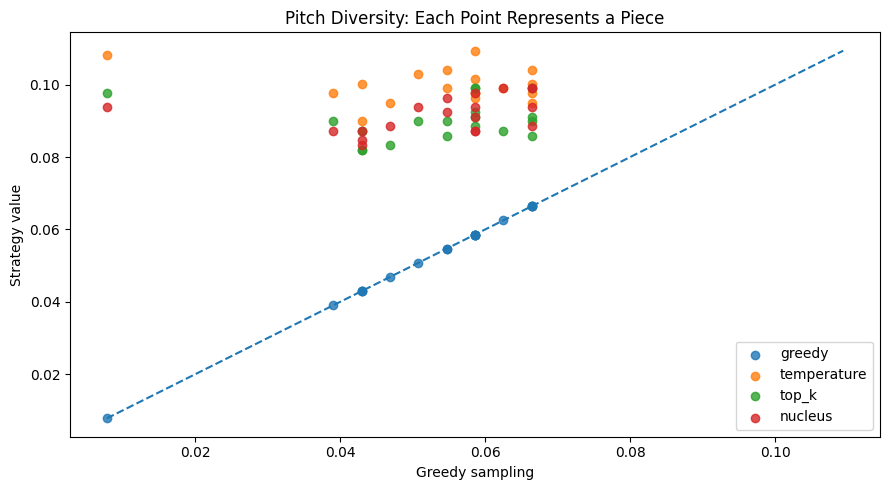

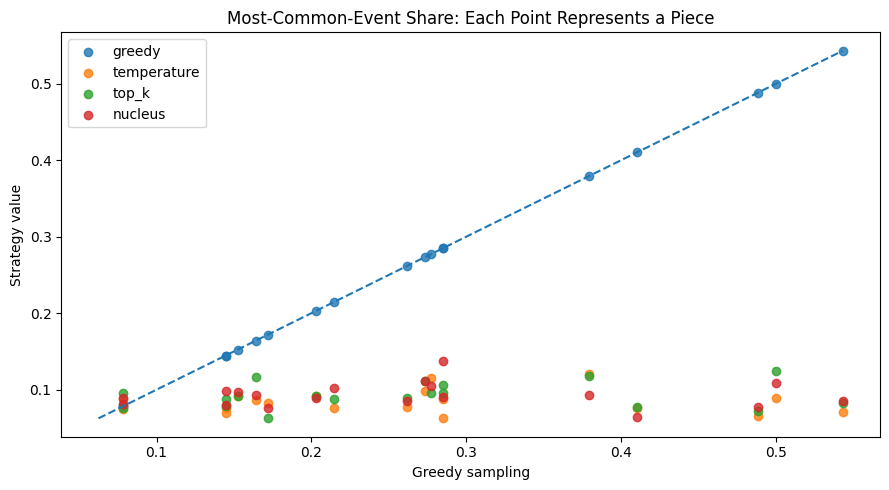

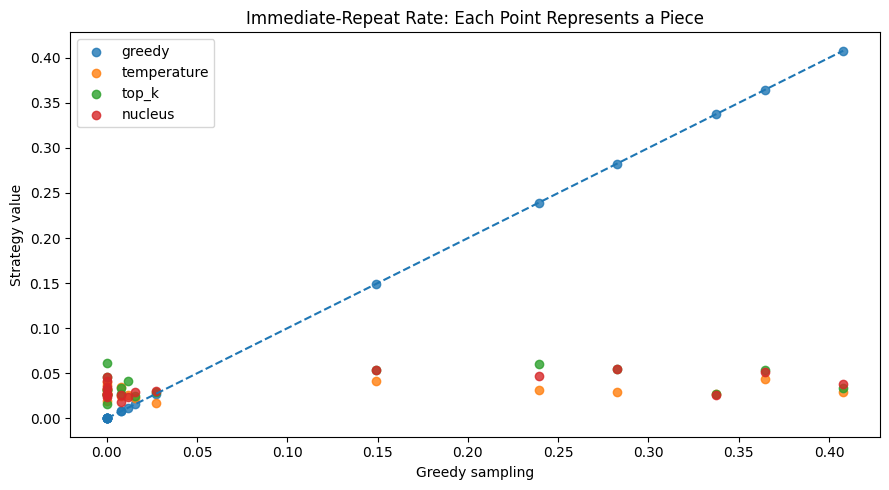

In [62]:

import pandas as pd
import matplotlib.pyplot as plt

metrics_to_plot = [
    ("pitch_diversity", "Pitch Diversity"),
    ("most_common_event_share", "Most-Common-Event Share"),
    ("immediate_repeat_rate", "Immediate-Repeat Rate")
]

# Average the 3 random-seed runs for each piece and strategy
piece_means = (
    robustness_df
    .groupby(["piece", "strategy"], as_index=False)[
        [metric for metric, _ in metrics_to_plot]
    ]
    .mean()
)

strategy_order = ["greedy", "temperature", "top_k", "nucleus"]

for metric, title in metrics_to_plot:
    plot_data = piece_means.pivot(
        index="piece",
        columns="strategy",
        values=metric
    )

    # Ensure consistent strategy order
    plot_data = plot_data[strategy_order]

    plt.figure(figsize=(9, 5))

    for strategy in strategy_order:
        plt.scatter(
            plot_data["greedy"],
            plot_data[strategy],
            label=strategy,
            alpha=0.8
        )

    # Reference line: same value as greedy
    lower = min(plot_data.min().min(), plot_data.max().min())
    upper = max(plot_data.max().max(), plot_data.min().max())
    plt.plot([lower, upper], [lower, upper], linestyle="--")

    plt.xlabel("Greedy sampling")
    plt.ylabel("Strategy value")
    plt.title(f"{title}: Each Point Represents a Piece")
    plt.legend()
    plt.tight_layout()
    plt.show()

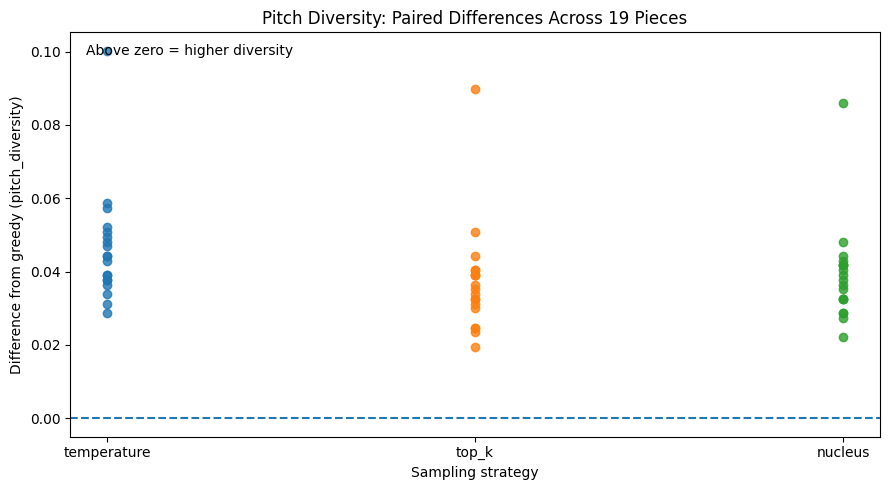

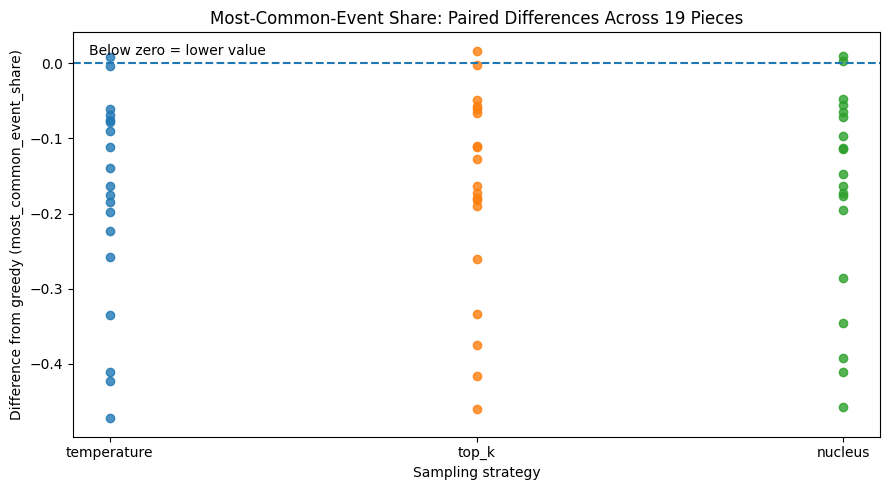

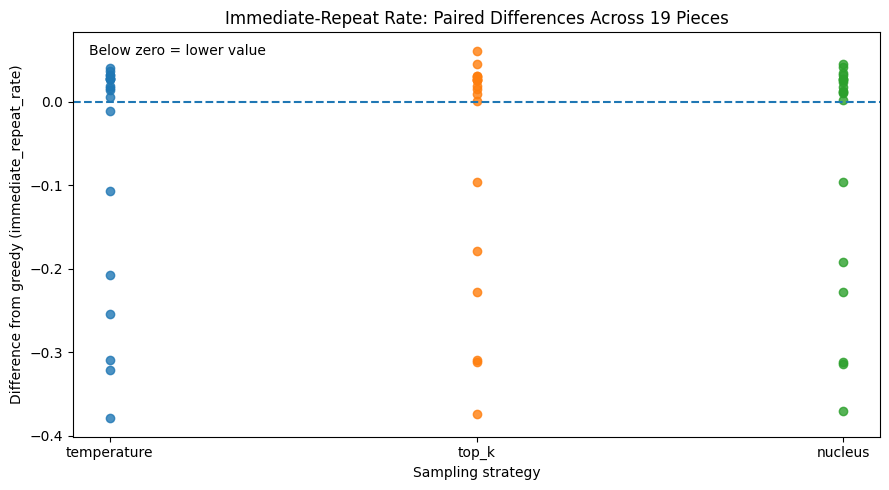

In [63]:

import pandas as pd
import matplotlib.pyplot as plt

metrics = [
    ("pitch_diversity", "Pitch Diversity", "higher"),
    ("most_common_event_share", "Most-Common-Event Share", "lower"),
    ("immediate_repeat_rate", "Immediate-Repeat Rate", "lower")
]

strategies = ["temperature", "top_k", "nucleus"]

# Average runs within each piece and strategy
piece_means = (
    robustness_df
    .groupby(["piece", "strategy"], as_index=False)[
        ["pitch_diversity", "most_common_event_share",
         "immediate_repeat_rate"]
    ]
    .mean()
)

# Put each strategy side by side for paired comparisons
paired = piece_means.pivot(
    index="piece",
    columns="strategy",
    values=[
        "pitch_diversity",
        "most_common_event_share",
        "immediate_repeat_rate"
    ]
)

for metric, title, preferred_direction in metrics:
    plt.figure(figsize=(9, 5))

    for strategy in strategies:
        differences = (
            paired[(metric, strategy)]
            - paired[(metric, "greedy")]
        )

        plt.scatter(
            [strategy] * len(differences),
            differences,
            alpha=0.8
        )

    # Zero means equal to greedy
    plt.axhline(0, linestyle="--")

    plt.xlabel("Sampling strategy")
    plt.ylabel(f"Difference from greedy ({metric})")
    plt.title(f"{title}: Paired Differences Across 19 Pieces")

    if preferred_direction == "higher":
        plt.text(
            0.02, 0.97,
            "Above zero = higher diversity",
            transform=plt.gca().transAxes,
            va="top"
        )
    else:
        plt.text(
            0.02, 0.97,
            "Below zero = lower value",
            transform=plt.gca().transAxes,
            va="top"
        )

    plt.tight_layout()
    plt.show()